# exp1_resource_obs — 2×2 analysis (03_GT, journal version)

Axis 1 of the journal paper (categorical 2×2), first batch of runs with the
**03_GT** code. Compared with the AIS 2026 runs (02_GT_AIS), the agents now get:

- the **homeostatic reward** p_i = meal_i·(1 − h_i), so r_i = (1−α)·p_i + α·ẽ_i ∈ [0, 1] for every α;
- the **individual emotions of the 5 other agents** (`EMOTION_TYPE = "vector"`, 7-dim observation)
  instead of their mean — the empathic reward term is still the mean;
- `see_emotions=False` means **uniform noise** in the emotion slots (precision ρ = 0), no longer a constant 0;
- the fixes of the "stored action ≠ played action" bug and of `env.reset()`.

These runs are therefore **not comparable bit for bit with the AIS results**.

**Design** — 2×2 factorial, `see_emotions` × `alpha`, all with `see_resource=True`:

| cell | condition | `see_emotions` (ρ) | `alpha` |
|---|---|---|---|
| A | `A_res_blind_non_empathic` | False (0) | 0.0 |
| B | `B_res_blind_reward_empathic` | False (0) | 0.5 |
| C | `C_res_sees_ignores` | True (1) | 0.0 |
| D | `D_res_full_empathy` | True (1) | 0.5 |

**Three metrics**

- **Depletion step** (`total_steps`) — how long the common pool survives.
  The episode terminates when `resource <= 0`, so this is literally the step at
  which the resource is depleted. *Sustainability.*
- **Gini coefficient of access to the resource** (`gini_meals`) — inequality of
  meal counts across the 6 agents within an episode. *Fairness.*
- **Personal reward** — mean over the 6 agents of the episode's summed
  homeostatic reward p_i (`total_personal_reward_*`). *Individual welfare*, new
  with the homeostatic scheme.

**Questions** (from `EXPERIMENT_TRACKER.md`, axis 1): 2×2 ANOVA on each metric,
the **C vs A** contrast (does the emotional signal still carry information once
`r_t` is visible?), and — together with `exp2_replication_no_res` once it has
run — whether resource observation interacts with the 2×2 and must be kept as a
factor in axes 2 and 3.

**Run batch** — the folder analysed is set by `RUN_BATCH` (§1). Currently
`beta3/global_v1`: the overnight batch 3 of `main_beta.py` (27/10/2026,
`reward_scheme='homeostatic_signed'` — signed empathic term —, `learn_every=4`,
500 episodes, dense evaluation over the first 20 episodes plus one before
training, 10 runs per cell: 3 from the 27/10 batch, seeds 906xxx, 7 from the
tablet batch, seeds 806xxx). It differs from the first `exp1_resource_obs`
campaign (`reward_scheme='homeostatic'`), so the two batches are analysed
separately, never pooled. Set `RUN_BATCH = "exp1_resource_obs"` to go back.

Analyses use the **greedy evaluation episodes only** (`phase='eval'`, ε = 0, no
learning). Only §13 writes to disk (figures, in `03_GT/figures/exp1_resource_obs/`, or a
`<batch>` subfolder of it when `RUN_BATCH` is not the exp1 folder).


## 1. Setup

In [1]:
# statsmodels supplies the ANOVA / Tukey HSD machinery used below and is not
# part of this repo's base environment (see requirements.txt).
try:
    import statsmodels.api as _sm
except ImportError:
    %pip install statsmodels
    import importlib
    importlib.invalidate_caches()


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\evann\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from IPython.display import display

EXPERIMENT = "exp1_resource_obs"
# Folder of csv_results/ holding the runs to analyse. One batch at a time: the
# batches differ in reward scheme / learner settings and must not be pooled.
#   "exp1_resource_obs" -- first 03_GT campaign, reward_scheme='homeostatic'
#   "beta3/global_v1"   -- main_beta.py batch 3 (27/10/2026): homeostatic_signed,
#                          learn_every=4, 500 episodes, 10 runs per cell
#                          (seeds 906xxx: 3 runs, 806xxx: 7 runs on the tablet)
RUN_BATCH = "beta3/global_v1"
RESULTS_DIR = Path("..") / "csv_results" / RUN_BATCH
BATCH_TAG = RUN_BATCH.replace("/", "_")

LAST_N_EVAL = 10      # eval episodes averaged to define "end of training"
ALPHA_LEVEL = 0.05    # significance threshold
TARGET_SEEDS = 20     # replications per condition targeted for the full campaign

# Replications excluded from the analysis. main_gt_ais.py writes the seed as
# 102 + 1000 * condition_idx + simulation and main_beta.py as
# BASE_SEED + 1000 * variant + 100 * condition_idx + run (BASE_SEED = 900_000,
# then 800_000 for the tablet batch), so the replication id -- the part shared
# by the four cells -- is seed % 100, prefixed by the BASE_SEED digit for
# main_beta runs (e.g. 803, 903) so the two beta3 batches do not collide.
# Nothing is ever deleted from csv_results/, runs are only filtered at load time.
DROPPED_REPLICATIONS: set[int] = set()

# Runs with fewer training episodes than the longest run of the batch were
# interrupted (e.g. beta3 A seed906000: 251/500 episodes, no weights) and are
# dropped at load time.
DROP_INCOMPLETE_RUNS = True

print(f"experiment : {EXPERIMENT}   (batch: {RUN_BATCH})")
print(f"data       : {RESULTS_DIR.resolve()}")


experiment : exp1_resource_obs   (batch: beta3/global_v1)
data       : C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\03_GT\csv_results\beta3\global_v1


In [3]:
# chart chrome: recessive grid and axes, text in neutral ink, series colour
# reserved for the marks themselves.
SURFACE = "#fcfcfb"
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "baseline": "#c3c2b7"}

# categorical slots (fixed order, never cycled)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
# ordinal blue ramp, steps 250-650: light end still clears 2:1 on this surface
ORDINAL_BLUE = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": INK["baseline"], "axes.linewidth": 1.0,
    "axes.labelcolor": INK["secondary"], "axes.labelsize": 10,
    "axes.titlecolor": INK["primary"], "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": INK["grid"], "grid.linewidth": 0.8,
    "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
    "text.color": INK["primary"],
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0,
})

METRIC_LABEL = {
    "depletion_step": "Depletion step (steps before the pool empties)",
    "gini_meals": "Gini coefficient of meals",
    "total_meals": "Total meals consumed per episode",
    "personal_reward": "Personal reward per agent (episode sum)",
}
METRICS = ["depletion_step", "gini_meals", "personal_reward"]


## 2. Load the runs

Every condition parameter is a column of the summary CSVs, so loading is a plain glob + concat.

In [4]:
def load_summaries(results_dir: Path) -> pd.DataFrame:
    """Concatenate every *_episode_summary.csv of one experiment folder.

    The runner writes all condition parameters as columns, so no filename
    parsing is needed (unlike the older EUMAS notebooks).
    """
    files = sorted(results_dir.glob("*_episode_summary.csv"))
    if not files:
        raise FileNotFoundError(f"no *_episode_summary.csv under {results_dir.resolve()}")
    frames = []
    for path in files:
        one = pd.read_csv(path)
        one["source_file"] = path.name
        frames.append(one)
    return pd.concat(frames, ignore_index=True)


df = load_summaries(RESULTS_DIR)
print(f"{df['source_file'].nunique()} run files, {len(df)} episode rows\n")

# -- replication filter (DROPPED_REPLICATIONS, section 1) ---------------------
# -- incomplete runs (DROP_INCOMPLETE_RUNS, section 1) -------------------------
# last train episode reached, not the row count: C seed806202 finished (weights
# saved, all eval episodes) but its train row 377 is missing from the CSV.
train_per_run = df[df["phase"] == "train"].groupby("source_file")["episode"].max() + 1
incomplete = sorted(train_per_run.index[train_per_run < train_per_run.max()])
if incomplete:
    print(f"{len(incomplete)} incomplete run(s) (< {train_per_run.max()} train episodes):")
    for name in incomplete:
        print(f"    {name}  ({train_per_run[name]} train episodes)")
    if DROP_INCOMPLETE_RUNS:
        df = df[~df["source_file"].isin(incomplete)].reset_index(drop=True)
        print(f"-> dropped; {df['source_file'].nunique()} run files kept, "
              f"{len(df)} episode rows\n")
    else:
        print("-> KEPT (DROP_INCOMPLETE_RUNS = False)\n")

df["replication"] = df["seed"] % 100 + 100 * (df["seed"] // 100_000)
if DROPPED_REPLICATIONS:
    keep = ~df["replication"].isin(DROPPED_REPLICATIONS)
    excluded = sorted(df.loc[~keep, "source_file"].unique())
    df = df.loc[keep].reset_index(drop=True)
    print(f"dropped replication(s) {sorted(DROPPED_REPLICATIONS)} -> "
          f"{len(excluded)} run files excluded")
    for name in excluded:
        print(f"    {name}")
    print(f"{df['source_file'].nunique()} run files kept, "
          f"{len(df)} episode rows\n")

inventory = (
    df.groupby("condition", observed=True)
      .agg(seeds=("seed", "nunique"),
           runs=("source_file", "nunique"),
           train_episodes=("phase", lambda s: int((s == "train").sum())),
           eval_episodes=("phase", lambda s: int((s == "eval").sum())))
      .sort_index()
)
inventory["seeds_missing_vs_target"] = TARGET_SEEDS - inventory["seeds"]
display(inventory)

if (inventory["seeds"] < TARGET_SEEDS).any():
    worst = int(inventory["seeds"].min())
    print(f"WARNING: only {worst}-{int(inventory['seeds'].max())} seeds per condition "
          f"(target {TARGET_SEEDS}). Every test below is underpowered; treat the "
          f"p-values as provisional until the full campaign has landed.")
else:
    print(f"All conditions at the {TARGET_SEEDS}-seed target.")


40 run files, 22376 episode rows

2 incomplete run(s) (< 500 train episodes):
    A_res_blind_non_empathic_seed906000_episode_summary.csv  (251 train episodes)
    C_res_sees_ignores_seed806204_episode_summary.csv  (401 train episodes)
-> dropped; 38 run files kept, 21621 episode rows



,seeds,runs,train_episodes,eval_episodes,seeds_missing_vs_target
condition,,,,,
A_res_blind_non_empathic,9,9,4500,621,11
B_res_blind_reward_empathic,10,10,5000,690,10
C_res_sees_ignores,9,9,4499,621,11
D_res_full_empathy,10,10,5000,690,10


## 3. Derived metrics and data integrity

Two things are checked before any test:

1. **Duplicated episodes** — a run written twice would silently inflate *n*.
2. **Right-censoring of the depletion step** — an episode that reaches
   `max_steps` with resource left never depleted the pool, so its "depletion
   step" is only a lower bound. The censoring rate qualifies every
   depletion-step result below.

In [5]:
# --- metrics -----------------------------------------------------------------
# depletion step: the episode ends when the pool hits 0 (env_gt_ais.py, done =
# resource <= 0), so total_steps IS the depletion step -- except when the
# episode is cut off at max_steps with resource left, which is right-censoring.
df["depletion_step"] = df["total_steps"]
df["censored"] = (df["total_steps"] >= df["max_steps"]) & (df["resource_remaining"] > 0)

meal_cols = [c for c in df.columns if re.fullmatch(r"meals_\d+", c)]
df["total_meals"] = df[meal_cols].sum(axis=1)

# homeostatic welfare: mean over agents of the summed personal reward p_i
personal_cols = [c for c in df.columns if re.fullmatch(r"total_personal_reward_\d+", c)]
df["personal_reward"] = df[personal_cols].mean(axis=1)

# final analyses use the greedy evaluation episodes only (epsilon = 0, no
# learning): the train rows carry exploration noise. See README.md.
ev = df[df["phase"] == "eval"].copy()

# --- integrity ---------------------------------------------------------------
dupes = int(df.duplicated(subset=["condition", "seed", "phase", "episode"]).sum())
eval_per_run = ev.groupby("source_file", observed=True).size()
print(f"duplicate (condition, seed, phase, episode) rows : {dupes}")
print(f"eval episodes per run : min {eval_per_run.min()}, max {eval_per_run.max()}")
print(f"agents per episode    : {len(meal_cols)}")
assert dupes == 0, "duplicated episode rows -- check for a re-run written twice"

# --- censoring ---------------------------------------------------------------
censoring = (
    ev.groupby("condition", observed=True)
      .agg(eval_episodes=("censored", "size"),
           censored_episodes=("censored", "sum"),
           censored_rate=("censored", "mean"),
           max_steps=("max_steps", "max"))
      .sort_index()
)
display(censoring.style.format({"censored_rate": "{:.1%}"}))

overall = ev["censored"].mean()
if overall > 0.10:
    print(f"WARNING: {overall:.1%} of eval episodes never depleted the pool and were "
          f"cut off at max_steps={int(ev['max_steps'].max())}. For those, the depletion "
          f"step is a LOWER BOUND, so every depletion-step result below is conservative "
          f"and compressed towards the ceiling -- conditions differing only above the "
          f"cap cannot be separated by these tests.")
else:
    print(f"Censoring is limited ({overall:.1%} of eval episodes); depletion step is "
          f"observed almost everywhere.")


duplicate (condition, seed, phase, episode) rows : 0
eval episodes per run : min 69, max 69
agents per episode    : 6


,eval_episodes,censored_episodes,censored_rate,max_steps
condition,,,,
A_res_blind_non_empathic,621,114,18.4%,1000
B_res_blind_reward_empathic,690,242,35.1%,1000
C_res_sees_ignores,621,59,9.5%,1000
D_res_full_empathy,690,263,38.1%,1000


## 4. Helper functions

Every statistical helper takes the metric column as an argument and is called once per metric — no copy-paste between depletion step and Gini.

In [6]:
def mean_ci(values: np.ndarray, conf: float = 0.95) -> tuple[float, float]:
    """Mean and half-width of its t-based CI (0 when n < 2)."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2:
        return (float(values.mean()) if n else np.nan), 0.0
    half = stats.t.ppf(1 - (1 - conf) / 2, n - 1) * values.std(ddof=1) / np.sqrt(n)
    return float(values.mean()), float(half)


def holm(pvals) -> np.ndarray:
    """Holm-Bonferroni adjusted p-values (step-down, monotone)."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adjusted[idx] = min(running, 1.0)
    return adjusted


def hedges_g(a, b) -> tuple[float, float, float]:
    """Hedges' g (bias-corrected Cohen's d) and its 95% CI."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    d = (a.mean() - b.mean()) / pooled
    g = d * (1 - 3 / (4 * (na + nb) - 9))
    se = np.sqrt((na + nb) / (na * nb) + g ** 2 / (2 * (na + nb - 2)))
    return float(g), float(g - 1.96 * se), float(g + 1.96 * se)


def stars(p: float) -> str:
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"


def end_of_training(eval_df: pd.DataFrame, group_keys: list[str],
                    last_n: int = LAST_N_EVAL) -> pd.DataFrame:
    """One row per (condition, seed): mean over the last `last_n` eval episodes.

    This is the unit of analysis for every test below -- the seed, not the
    episode, is the independent replication.
    """
    tail = (eval_df.sort_values("episode")
                   .groupby(group_keys + ["seed"], observed=True)
                   .tail(last_n))
    out = (tail.groupby(group_keys + ["seed"], observed=True)
               .agg(depletion_step=("depletion_step", "mean"),
                    gini_meals=("gini_meals", "mean"),
                    total_meals=("total_meals", "mean"),
                    personal_reward=("personal_reward", "mean"),
                    censored_frac=("censored", "mean"),
                    n_eval=("episode", "size"),
                    from_episode=("episode", "min"),
                    to_episode=("episode", "max"))
               .reset_index())
    return out


def describe_groups(seed_df: pd.DataFrame, group_col: str) -> pd.DataFrame:
    """Mean +/- 95% CI and SD per group, for every metric in METRICS."""
    rows = []
    for key, sub in seed_df.groupby(group_col, observed=True):
        row = {group_col: key, "n_seeds": len(sub)}
        for metric in METRICS:
            m, half = mean_ci(sub[metric])
            row[f"{metric}_mean"] = m
            row[f"{metric}_ci95"] = half
            row[f"{metric}_sd"] = sub[metric].std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)


def assumption_checks(residuals, groups) -> pd.DataFrame:
    """Shapiro-Wilk on the model residuals, Levene on the raw groups."""
    sw_stat, sw_p = stats.shapiro(residuals)
    lv_stat, lv_p = stats.levene(*groups)
    return pd.DataFrame([
        {"test": "Shapiro-Wilk (residual normality)", "statistic": sw_stat, "p": sw_p,
         "verdict": "ok" if sw_p >= ALPHA_LEVEL else "violated -> read the rank test"},
        {"test": "Levene (homoscedasticity)", "statistic": lv_stat, "p": lv_p,
         "verdict": "ok" if lv_p >= ALPHA_LEVEL else "violated -> read the rank test"},
    ])


def pairwise_ranktests(seed_df: pd.DataFrame, metric: str, group_col: str,
                       order: list) -> pd.DataFrame:
    """All pairwise Mann-Whitney U tests with Holm-corrected p-values."""
    rows = []
    for i, left in enumerate(order):
        for right in order[i + 1:]:
            a = seed_df.loc[seed_df[group_col] == left, metric].to_numpy()
            b = seed_df.loc[seed_df[group_col] == right, metric].to_numpy()
            u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
            g, lo, hi = hedges_g(a, b)
            rows.append({"pair": f"{left} vs {right}", "U": u, "p_raw": p,
                         "mean_diff": a.mean() - b.mean(),
                         "hedges_g": g, "g_lo": lo, "g_hi": hi})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p_raw"])
    out["sig"] = out["p_holm"].map(stars)
    return out


SMOOTH_WINDOW = 5   # eval episodes averaged in the learning curves (0 = raw)


def learning_curve(ax, metric, series_specs, smooth=SMOOTH_WINDOW, show_ci=True,
                   clip=None):
    """Eval-phase metric vs episode, mean (+/- 95% CI) across seeds.

    `series_specs` is a list of {"data", "color", "label", "linestyle"} dicts --
    one entry per line, so identity is carried by colour AND dash pattern.
    `smooth` applies a centred rolling mean over eval episodes; with a handful of
    seeds the per-episode means are too noisy to judge convergence otherwise.
    `show_ci=False` past ~4 series: overlapping bands turn into an unreadable
    wash, and the per-seed spread is shown properly in the distribution figures.
    `clip` is a (low, high) bound for the band, e.g. (0, 1) for a Gini.
    """
    for spec in series_specs:
        agg = (spec["data"].groupby("episode", observed=True)[metric]
                           .agg(["mean", "std", "count"]))
        n = agg["count"].to_numpy()
        half = pd.Series(
            np.where(n > 1,
                     stats.t.ppf(0.975, np.maximum(n - 1, 1))
                     * np.nan_to_num(agg["std"].to_numpy()) / np.sqrt(np.maximum(n, 1)),
                     0.0),
            index=agg.index)
        centre = agg["mean"]
        if smooth and smooth > 1:
            centre = centre.rolling(smooth, center=True, min_periods=1).mean()
            half = half.rolling(smooth, center=True, min_periods=1).mean()
        if show_ci:
            low, high = centre - half, centre + half
            if clip is not None:
                low, high = low.clip(lower=clip[0]), high.clip(upper=clip[1])
            ax.fill_between(agg.index, low, high, color=spec["color"],
                            alpha=0.13, linewidth=0)
        ax.plot(agg.index, centre, color=spec["color"], lw=2,
                linestyle=spec.get("linestyle", "-"), label=spec["label"])
    ax.set_xlabel("Training episode")
    ax.set_ylabel(METRIC_LABEL[metric])


def box_strip(ax, seed_df, metric, group_col, order, colors, ticklabels=None):
    """Boxplot with every seed overlaid -- mandatory at these sample sizes."""
    groups = [seed_df.loc[seed_df[group_col] == g, metric].to_numpy() for g in order]
    bp = ax.boxplot(groups, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK["primary"], lw=1.6),
                    whiskerprops=dict(color=INK["baseline"], lw=1.2),
                    capprops=dict(color=INK["baseline"], lw=1.2))
    for patch, colour in zip(bp["boxes"], colors):
        patch.set_facecolor(colour)
        patch.set_alpha(0.22)
        patch.set_edgecolor(colour)
        patch.set_linewidth(1.4)
    rng = np.random.default_rng(0)
    for i, (values, colour) in enumerate(zip(groups, colors), start=1):
        jitter = i + rng.uniform(-0.13, 0.13, size=len(values))
        ax.scatter(jitter, values, s=34, color=colour, zorder=3,
                   edgecolor=SURFACE, linewidth=1.2)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(ticklabels or [str(o) for o in order])
    ax.set_ylabel(METRIC_LABEL[metric])


## 5. The 2×2 factor grid

`condition`, `see_emotions` and `alpha` are redundant by construction; the check
below makes that explicit so the ANOVA formula can be trusted.

In [7]:
CONDITIONS = sorted(ev["condition"].unique())
CELL_LETTER = {c: c[0] for c in CONDITIONS}          # A_res_... -> "A"

SEE_LABEL = {False: "emotions hidden", True: "emotions visible"}
ALPHA_LABEL = {0.0: "α = 0.0 (non-empathic)", 0.5: "α = 0.5 (empathic)"}

# colour follows the entity (the emotion channel); alpha is carried by position
# and dash pattern, never by a third hue.
SEE_COLOR = {False: CAT[0], True: CAT[1]}
ALPHA_STYLE = {0.0: "-", 0.5: "--"}

grid = (ev.groupby(["condition", "see_emotions", "alpha", "see_resource",
                   "emotion_precision", "see_own_meals", "gamma", "reward_scheme"],
                  observed=True, dropna=False)
          .size().rename("eval_rows").reset_index().sort_values("condition"))
grid.insert(0, "cell", grid["condition"].map(CELL_LETTER))
display(grid)

assert grid["see_resource"].all(), "exp1 requires see_resource=True everywhere"
assert len(grid) == 4, f"expected the 4 cells of the 2x2, found {len(grid)}"
# 03_GT: see_emotions is precision 1 (exact) vs 0 (uniform noise), and every
# cell must use the homeostatic reward -- otherwise the runs come from 02_GT_AIS.
assert (grid["emotion_precision"] == grid["see_emotions"].astype(float)).all(), \
    "emotion_precision should be 1 when emotions are seen and 0 otherwise"
# 'homeostatic' = first 03_GT batch, 'homeostatic_restraint' = restraint bonus
# (default since 05/10/2026), 'homeostatic_signed' = signed empathic term
# (main_beta.py global_v1, 27/10/2026). never mix them in one analysis.
assert grid["reward_scheme"].nunique() == 1, "mixed reward schemes in one folder"
assert grid["reward_scheme"].iloc[0] in ("homeostatic", "homeostatic_restraint", "homeostatic_signed"), "expected 03_GT runs"
print("reward scheme:", grid["reward_scheme"].iloc[0])
assert df["gamma_others"].isna().all(), "exp1 uses the one-head DQN (gamma_others empty)"


,cell,condition,see_emotions,alpha,see_resource,emotion_precision,see_own_meals,gamma,reward_scheme,eval_rows
0,A,A_res_blind_non_empathic,False,0.0,True,0.0,True,0.99,homeostatic_signed,621
1,B,B_res_blind_reward_empathic,False,0.5,True,0.0,True,0.99,homeostatic_signed,690
2,C,C_res_sees_ignores,True,0.0,True,1.0,True,0.99,homeostatic_signed,621
3,D,D_res_full_empathy,True,0.5,True,1.0,True,0.99,homeostatic_signed,690


reward scheme: homeostatic_signed


## 6. Learning curves

Do the agents actually learn under the corrected regime, and have the metrics
plateaued by the end of training? If they have not, the end-of-training window
below measures a moving target rather than a converged policy.

Colour = emotion channel, dash = empathic weight, so the four cells stay
distinguishable without a third hue.

findfont: Failed to find font weight semibold, now using 700.


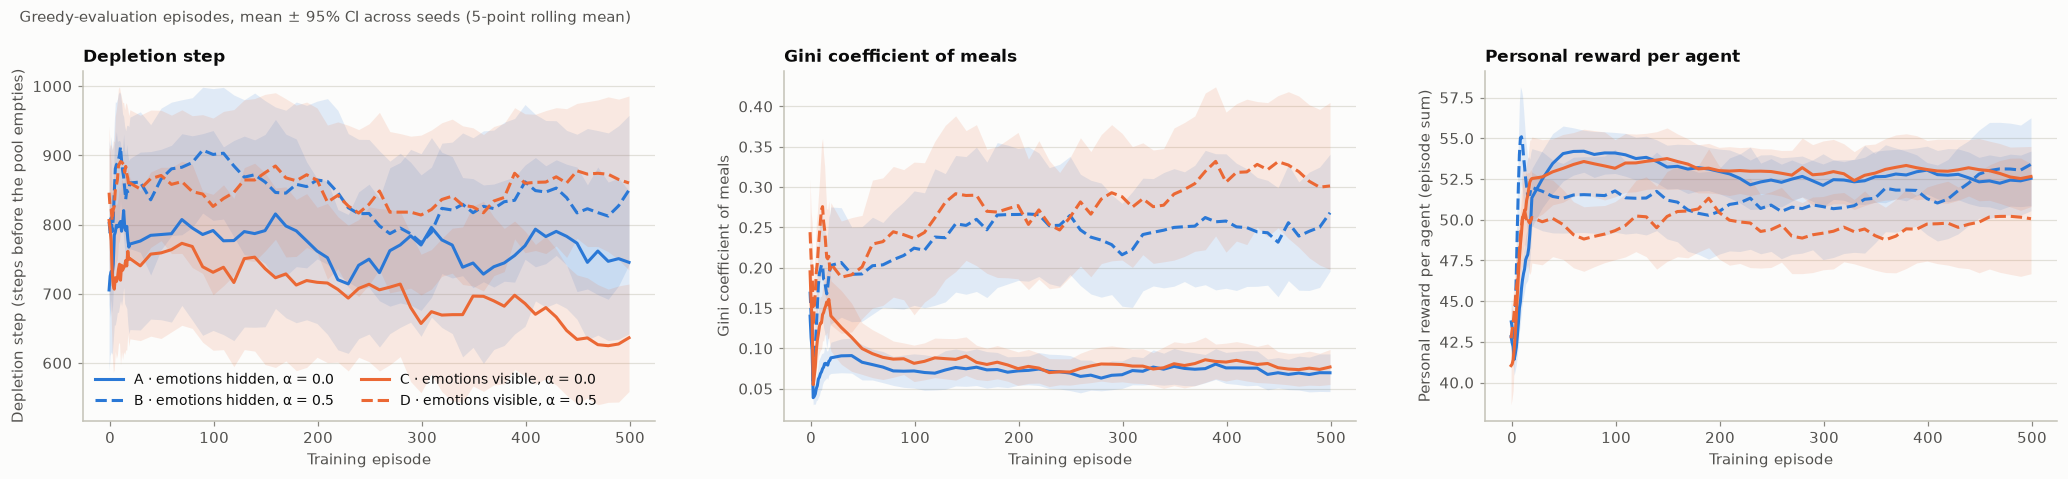

In [8]:
specs = [{"data": ev[(ev["see_emotions"] == see) & (ev["alpha"] == a)],
          "color": SEE_COLOR[see], "linestyle": ALPHA_STYLE[a],
          "label": f"{CELL_LETTER[cond]} · {SEE_LABEL[see]}, α = {a}"}
         for cond, see, a in grid[["condition", "see_emotions", "alpha"]].itertuples(index=False)]

fig, axes = plt.subplots(1, len(METRICS), figsize=(6.3 * len(METRICS), 4.4))
for ax, metric in zip(axes, METRICS):
    learning_curve(ax, metric, specs, clip=(0, 1) if metric == "gini_meals" else None)
    ax.set_title(METRIC_LABEL[metric].split(" (")[0])
axes[0].legend(loc="lower left", ncols=2)
fig.suptitle(f"Greedy-evaluation episodes, mean ± 95% CI across seeds "
             f"({SMOOTH_WINDOW}-point rolling mean)",
             x=0.012, ha="left", color=INK["secondary"], fontsize=10)
fig.tight_layout()
plt.show()


## 7. End-of-training aggregation

The unit of analysis is **one row per (condition, seed)**: the mean over the last
`LAST_N_EVAL` greedy evaluation episodes. The seed is the independent
replication — averaging over episodes first avoids treating correlated
episodes of one run as independent observations.

In [9]:
GROUP_KEYS = ["condition", "see_emotions", "alpha"]
seed_df = end_of_training(ev, GROUP_KEYS)
seed_df.insert(0, "cell", seed_df["condition"].map(CELL_LETTER))

print(f"{len(seed_df)} seed-level rows "
      f"({seed_df['n_eval'].min()}-{seed_df['n_eval'].max()} eval episodes each, "
      f"episodes {seed_df['from_episode'].min()}-{seed_df['to_episode'].max()})")
display(seed_df.sort_values(["condition", "seed"]).reset_index(drop=True))


38 seed-level rows (10-10 eval episodes each, episodes 409-499)


,cell,condition,see_emotions,alpha,seed,depletion_step,gini_meals,total_meals,personal_reward,censored_frac,n_eval,from_episode,to_episode
0,A,A_res_blind_non_empathic,False,0.0,806000,740.9,0.078707,499.8,52.170000,0.1,10,409,499
1,A,A_res_blind_non_empathic,False,0.0,806001,761.4,0.082043,499.9,52.590000,0.1,10,409,499
2,A,A_res_blind_non_empathic,False,0.0,806002,748.7,0.055620,499.8,52.108333,0.1,10,409,499
3,A,A_res_blind_non_empathic,False,0.0,806003,751.7,0.079456,499.9,52.597500,0.1,10,409,499
4,A,A_res_blind_non_empathic,False,0.0,806004,728.1,0.066467,500.0,52.899167,0.0,10,409,499
5,A,A_res_blind_non_empathic,False,0.0,806005,791.9,0.087145,499.6,53.435000,0.3,10,409,499
6,A,A_res_blind_non_empathic,False,0.0,806006,752.8,0.066453,499.9,52.165833,0.1,10,409,499
7,A,A_res_blind_non_empathic,False,0.0,906001,843.7,0.067573,499.5,52.724167,0.3,10,409,499
8,A,A_res_blind_non_empathic,False,0.0,906002,796.8,0.060375,499.8,52.794167,0.2,10,409,499
9,B,B_res_blind_reward_empathic,False,0.5,806100,825.9,0.257237,499.4,52.828333,0.2,10,409,499


In [10]:
summary = describe_groups(seed_df, "condition")
summary.insert(0, "cell", summary["condition"].map(CELL_LETTER))
display(summary.style.format({c: "{:.3f}" for c in summary.columns
                              if summary[c].dtype.kind == "f"}))


,cell,condition,n_seeds,depletion_step_mean,depletion_step_ci95,depletion_step_sd,gini_meals_mean,gini_meals_ci95,gini_meals_sd,personal_reward_mean,personal_reward_ci95,personal_reward_sd
0,A,A_res_blind_non_empathic,9,768.444,27.673,36.001,0.072,0.008,0.011,52.609,0.328,0.426
1,B,B_res_blind_reward_empathic,10,832.430,25.695,35.920,0.245,0.023,0.032,52.452,1.286,1.797
2,C,C_res_sees_ignores,9,645.611,29.832,38.810,0.078,0.006,0.007,52.844,0.369,0.480
3,D,D_res_full_empathy,10,870.760,24.166,33.781,0.318,0.029,0.041,49.870,1.038,1.451


## 8. Two-way ANOVA

`metric ~ C(see_emotions) * C(alpha)`, type II sums of squares, with partial η²
as the effect size. Assumptions are checked first; the rank-based tests in §9 are
reported **alongside** the ANOVA, not instead of it, so a violated assumption
never leaves a result unstated.

In [11]:
def two_way_anova(data: pd.DataFrame, metric: str):
    """Type-II two-way ANOVA with partial eta squared."""
    model = ols(f"{metric} ~ C(see_emotions) * C(alpha)", data=data).fit()
    table = anova_lm(model, typ=2)
    ss_resid = table.loc["Residual", "sum_sq"]
    table["partial_eta_sq"] = table["sum_sq"] / (table["sum_sq"] + ss_resid)
    table.loc["Residual", "partial_eta_sq"] = np.nan
    table["sig"] = [stars(p) if pd.notna(p) else "" for p in table["PR(>F)"]]
    return model, table


TERM_LABEL = {"C(see_emotions)": "emotion observation",
              "C(alpha)": "empathic weight α",
              "C(see_emotions):C(alpha)": "observation × α interaction"}

anova_tables, models = {}, {}
for metric in METRICS:
    model, table = two_way_anova(seed_df, metric)
    models[metric], anova_tables[metric] = model, table

    print("=" * 78)
    print(f"{METRIC_LABEL[metric]}   (n = {len(seed_df)} seeds, "
          f"{seed_df['cell'].value_counts().min()}-{seed_df['cell'].value_counts().max()} per cell)")
    print("=" * 78)
    display(table.style.format({"sum_sq": "{:.4g}", "F": "{:.3f}",
                                "PR(>F)": "{:.4f}", "partial_eta_sq": "{:.3f}"},
                               na_rep="—"))
    cells_groups = [g[metric].to_numpy() for _, g in seed_df.groupby("condition", observed=True)]
    display(assumption_checks(model.resid, cells_groups)
            .style.format({"statistic": "{:.3f}", "p": "{:.4f}"}))


Depletion step (steps before the pool empties)   (n = 38 seeds, 9-10 per cell)


,sum_sq,df,F,PR(>F),partial_eta_sq,sig
C(see_emotions),1.373e+04,1.000000,10.534,0.0026,0.237,**
C(alpha),1.98e+05,1.000000,151.960,0.0000,0.817,***
C(see_emotions):C(alpha),6.152e+04,1.000000,47.213,0.0000,0.581,***
Residual,4.43e+04,34.000000,—,—,—,


,test,statistic,p,verdict
0,Shapiro-Wilk (residual normality),0.975,0.5451,ok
1,Levene (homoscedasticity),0.044,0.9873,ok


Gini coefficient of meals   (n = 38 seeds, 9-10 per cell)


,sum_sq,df,F,PR(>F),partial_eta_sq,sig
C(see_emotions),0.01619,1.000000,21.372,0.0001,0.386,***
C(alpha),0.4042,1.000000,533.388,0.0000,0.940,***
C(see_emotions):C(alpha),0.01051,1.000000,13.869,0.0007,0.290,***
Residual,0.02576,34.000000,—,—,—,


,test,statistic,p,verdict
0,Shapiro-Wilk (residual normality),0.950,0.0872,ok
1,Levene (homoscedasticity),4.667,0.0078,violated -> read the rank test


Personal reward per agent (episode sum)   (n = 38 seeds, 9-10 per cell)


,sum_sq,df,F,PR(>F),partial_eta_sq,sig
C(see_emotions),14.79,1.000000,9.796,0.0036,0.224,**
C(alpha),23.22,1.000000,15.381,0.0004,0.311,***
C(see_emotions):C(alpha),18.79,1.000000,12.449,0.0012,0.268,**
Residual,51.33,34.000000,—,—,—,


,test,statistic,p,verdict
0,Shapiro-Wilk (residual normality),0.961,0.2094,ok
1,Levene (homoscedasticity),3.869,0.0175,violated -> read the rank test


### Tukey HSD across the four cells

In [12]:
for metric in METRICS:
    print("=" * 78)
    print(f"Tukey HSD — {METRIC_LABEL[metric]}")
    print(pairwise_tukeyhsd(seed_df[metric], seed_df["cell"], alpha=ALPHA_LEVEL))


Tukey HSD — Depletion step (steps before the pool empties)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
     A      B   63.9856 0.0026   19.1922  108.7789   True
     A      C -122.8333    0.0 -168.7904  -76.8763   True
     A      D  102.3156    0.0   57.5222  147.1089   True
     B      C -186.8189    0.0 -231.6123 -142.0255   True
     B      D     38.33 0.1015   -5.2687   81.9287  False
     C      D  225.1489    0.0  180.3555  269.9423   True
---------------------------------------------------------
Tukey HSD — Gini coefficient of meals
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
     A      B   0.1732   0.0  0.1391  0.2074   True
     A      C   0.0062 0.963 -0.0288  0.0413  False
     A      D   0.2461   0.0  0.2119  0.2802   True
     B     

## 9. Rank-based backup

Kruskal–Wallis over the four cells, then all pairwise Mann–Whitney U tests with
Holm correction. With this many seeds per cell the rank tests have very little
resolution — they are here to show whether the parametric conclusions depend on
the normality assumption, not to replace them.

In [13]:
for metric in METRICS:
    groups = [seed_df.loc[seed_df["cell"] == c, metric].to_numpy()
              for c in sorted(seed_df["cell"].unique())]
    h, p = stats.kruskal(*groups)
    print("=" * 78)
    print(f"{METRIC_LABEL[metric]}")
    print(f"Kruskal-Wallis H = {h:.3f}, p = {p:.4f} {stars(p)}")
    display(pairwise_ranktests(seed_df, metric, "cell", sorted(seed_df["cell"].unique()))
            .style.format({"U": "{:.1f}", "p_raw": "{:.4f}", "p_holm": "{:.4f}",
                           "mean_diff": "{:.3f}", "hedges_g": "{:.2f}",
                           "g_lo": "{:.2f}", "g_hi": "{:.2f}"}))


Depletion step (steps before the pool empties)
Kruskal-Wallis H = 30.193, p = 0.0000 ***


,pair,U,p_raw,mean_diff,hedges_g,g_lo,g_hi,p_holm,sig
0,A vs B,8.0,0.0029,-63.986,-1.70,-2.77,-0.63,0.0058,**
1,A vs C,81.0,0.0004,122.833,3.13,1.70,4.55,0.0017,**
2,A vs D,2.0,0.0005,-102.316,-2.80,-4.11,-1.50,0.0017,**
3,B vs C,90.0,0.0003,186.819,4.78,2.94,6.63,0.0017,**
4,B vs D,20.0,0.0257,-38.330,-1.05,-1.99,-0.11,0.0257,*
5,C vs D,0.0,0.0003,-225.149,-5.94,-8.12,-3.75,0.0017,**


Gini coefficient of meals
Kruskal-Wallis H = 31.497, p = 0.0000 ***


,pair,U,p_raw,mean_diff,hedges_g,g_lo,g_hi,p_holm,sig
0,A vs B,0.0,0.0003,-0.173,-6.71,-9.14,-4.28,0.0017,**
1,A vs C,26.0,0.2164,-0.006,-0.65,-1.60,0.30,0.2164,ns
2,A vs D,0.0,0.0003,-0.246,-7.68,-10.42,-4.95,0.0017,**
3,B vs C,90.0,0.0003,0.167,6.63,4.22,9.03,0.0017,**
4,B vs D,4.0,0.0006,-0.073,-1.89,-2.97,-0.82,0.0017,**
5,C vs D,0.0,0.0003,-0.240,-7.60,-10.32,-4.89,0.0017,**


Personal reward per agent (episode sum)
Kruskal-Wallis H = 14.447, p = 0.0024 **


,pair,U,p_raw,mean_diff,hedges_g,g_lo,g_hi,p_holm,sig
0,A vs B,39.0,0.6534,0.157,0.11,-0.79,1.01,1.0000,ns
1,A vs C,35.0,0.6588,-0.235,-0.49,-1.43,0.45,1.0000,ns
2,A vs D,82.0,0.0029,2.739,2.39,1.18,3.59,0.0144,*
3,B vs C,47.0,0.9025,-0.392,-0.28,-1.18,0.63,1.0000,ns
4,B vs D,88.0,0.0046,2.582,1.51,0.51,2.52,0.0183,*
5,C vs D,84.0,0.0017,2.974,2.57,1.32,3.82,0.0100,*


## 10. Planned contrast: C vs A

**The key contrast of axis 1.** A and C differ only in whether the
agents see the others' emotional signal; both are non-empathic (α = 0) and both
already observe `r_t`. In the AIS manuscript the emotional signal was the *only*
information available, so an effect there was unsurprising. If C ≈ A now, the
"observation" effect was a proxy for resource information; if C still differs
from A, the affective channel carries something `r_t` does not.

This is a single a-priori comparison, so it is not part of the Holm family
above and is reported uncorrected — with the effect size, which is what should
be read at this sample size.

In [14]:
for metric in METRICS:
    a = seed_df.loc[seed_df["cell"] == "A", metric].to_numpy()
    c = seed_df.loc[seed_df["cell"] == "C", metric].to_numpy()
    welch = stats.ttest_ind(c, a, equal_var=False)
    u, p_u = stats.mannwhitneyu(c, a, alternative="two-sided")
    g, lo, hi = hedges_g(c, a)
    print("=" * 78)
    print(f"{METRIC_LABEL[metric]}")
    print(f"  A (emotions hidden, α=0) : {a.mean():8.3f}  (n={len(a)})")
    print(f"  C (emotions seen,   α=0) : {c.mean():8.3f}  (n={len(c)})")
    print(f"  difference C − A         : {c.mean() - a.mean():+8.3f}")
    print(f"  Welch t({welch.df:.1f}) = {welch.statistic:.3f}, "
          f"p = {welch.pvalue:.4f} {stars(welch.pvalue)}")
    print(f"  Mann-Whitney U = {u:.1f}, p = {p_u:.4f} {stars(p_u)}")
    print(f"  Hedges' g = {g:+.2f}  [{lo:+.2f}, {hi:+.2f}]"
          f"{'  (CI excludes 0)' if lo * hi > 0 else '  (CI includes 0)'}")


Depletion step (steps before the pool empties)
  A (emotions hidden, α=0) :  768.444  (n=9)
  C (emotions seen,   α=0) :  645.611  (n=9)
  difference C − A         : -122.833
  Welch t(15.9) = -6.961, p = 0.0000 ***
  Mann-Whitney U = 0.0, p = 0.0004 ***
  Hedges' g = -3.13  [-4.55, -1.70]  (CI excludes 0)
Gini coefficient of meals
  A (emotions hidden, α=0) :    0.072  (n=9)
  C (emotions seen,   α=0) :    0.078  (n=9)
  difference C − A         :   +0.006
  Welch t(14.2) = 1.440, p = 0.1716 ns
  Mann-Whitney U = 55.0, p = 0.2164 ns
  Hedges' g = +0.65  [-0.30, +1.60]  (CI includes 0)
Personal reward per agent (episode sum)
  A (emotions hidden, α=0) :   52.609  (n=9)
  C (emotions seen,   α=0) :   52.844  (n=9)
  difference C − A         :   +0.235
  Welch t(15.8) = 1.098, p = 0.2888 ns
  Mann-Whitney U = 46.0, p = 0.6588 ns
  Hedges' g = +0.49  [-0.45, +1.43]  (CI includes 0)


## 11. Figures

Left: interaction plot — the shape that answers "is the effect of α the same
whether or not emotions are observed?". Right: every seed, so the reader can see
the spread behind a 4-point mean rather than trusting an error bar.

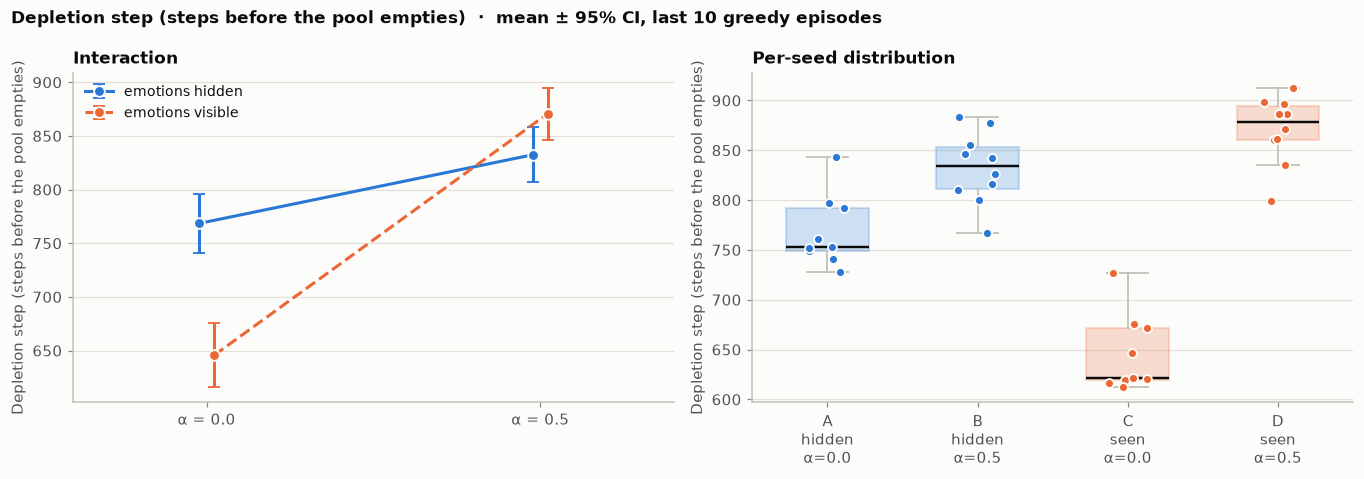

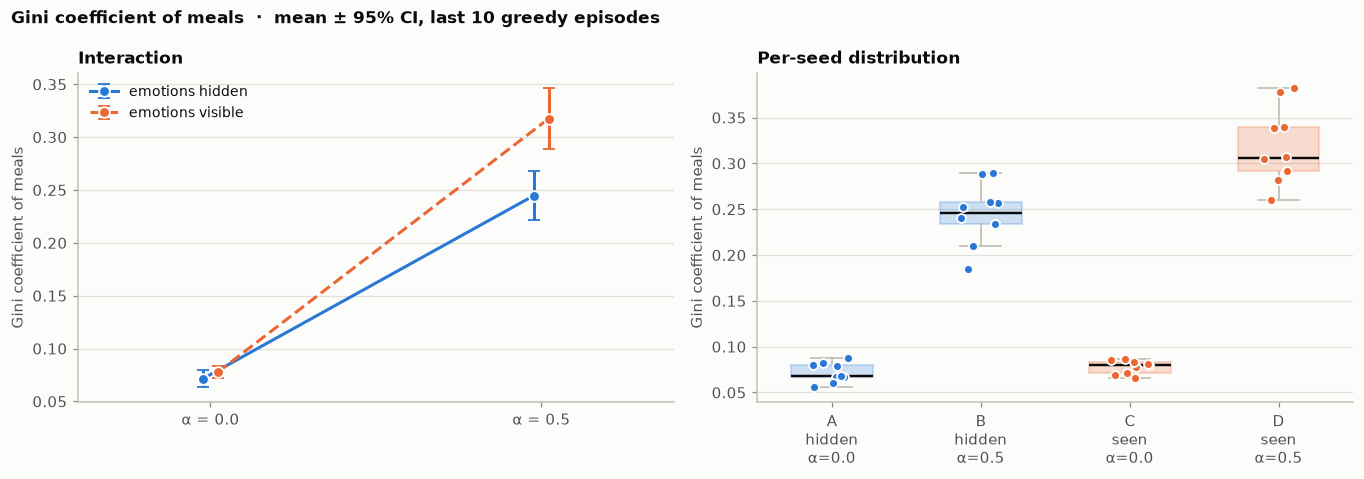

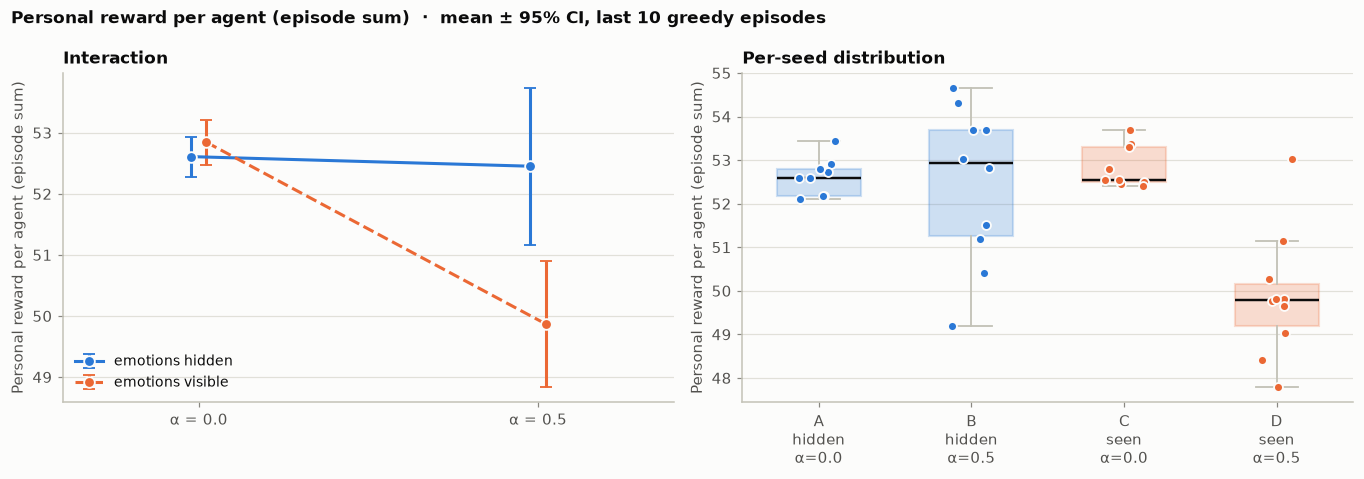

In [15]:
def interaction_plot(ax, data, metric):
    xpos = {a: i for i, a in enumerate(sorted(data["alpha"].unique()))}
    for k, see in enumerate([False, True]):
        sub = data[data["see_emotions"] == see]
        means, halves, xs = [], [], []
        for a, grp in sub.groupby("alpha", observed=True):
            m, half = mean_ci(grp[metric])
            means.append(m); halves.append(half)
            xs.append(xpos[a] + (k - 0.5) * 0.045)
        ax.errorbar(xs, means, yerr=halves, color=SEE_COLOR[see], lw=2,
                    marker="o", ms=7, capsize=4, mec=SURFACE, mew=1.2,
                    linestyle=["-", "--"][k], label=SEE_LABEL[see])
    ax.set_xticks(list(xpos.values()))
    ax.set_xticklabels([f"α = {a}" for a in xpos])
    ax.set_xlim(-0.4, len(xpos) - 0.6)
    ax.set_ylabel(METRIC_LABEL[metric])


order = sorted(seed_df["cell"].unique())
cell_colors = [SEE_COLOR[seed_df.loc[seed_df["cell"] == c, "see_emotions"].iloc[0]]
               for c in order]
ticklabels = [f"{c}\n{'seen' if seed_df.loc[seed_df.cell == c, 'see_emotions'].iloc[0] else 'hidden'}"
              f"\nα={seed_df.loc[seed_df.cell == c, 'alpha'].iloc[0]}" for c in order]

for metric in METRICS:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    interaction_plot(axes[0], seed_df, metric)
    axes[0].set_title("Interaction")
    axes[0].legend(loc="best")
    box_strip(axes[1], seed_df, metric, "cell", order, cell_colors, ticklabels)
    axes[1].set_title("Per-seed distribution")
    fig.suptitle(METRIC_LABEL[metric] + f"  ·  mean ± 95% CI, last {LAST_N_EVAL} "
                 f"greedy episodes", x=0.012, ha="left", fontsize=11,
                 fontweight="semibold")
    fig.tight_layout()
    plt.show()


## 12. Read-out

Conclusions are derived from the tables above rather than typed in, so they stay
correct as seeds are added.

In [16]:
from math import comb


def verdict(metric):
    table = anova_tables[metric]
    lines = []
    for term in ["C(see_emotions)", "C(alpha)", "C(see_emotions):C(alpha)"]:
        p = table.loc[term, "PR(>F)"]
        f = table.loc[term, "F"]
        eta = table.loc[term, "partial_eta_sq"]
        verdict_txt = "significant" if p < ALPHA_LEVEL else "not significant"
        lines.append(f"    {TERM_LABEL[term]:<28} F({table.loc[term, 'df']:.0f},"
                     f"{table.loc['Residual', 'df']:.0f}) = {f:6.3f}, p = {p:.4f} "
                     f"-> {verdict_txt} (partial η² = {eta:.3f})")
    return lines


print("=" * 78)
print(f"{EXPERIMENT} [{RUN_BATCH}] — {seed_df['seed'].nunique()} seeds total, "
      f"{seed_df['cell'].value_counts().min()}-{seed_df['cell'].value_counts().max()} per cell, "
      f"last {LAST_N_EVAL} greedy episodes")
print("=" * 78)
for metric in METRICS:
    print(f"\n  {METRIC_LABEL[metric]}")
    print("\n".join(verdict(metric)))
    means = seed_df.groupby("cell", observed=True)[metric].mean()
    print(f"    cell means: " + ", ".join(f"{c} = {v:.3f}" for c, v in means.items()))

# direction of the two headline effects
print("\n" + "-" * 78)
for metric in METRICS:
    by_alpha = seed_df.groupby("alpha", observed=True)[metric].mean()
    by_see = seed_df.groupby("see_emotions", observed=True)[metric].mean()
    d_alpha = by_alpha.loc[0.5] - by_alpha.loc[0.0]
    d_see = by_see.loc[True] - by_see.loc[False]
    name = METRIC_LABEL[metric].split(" (")[0]
    print(f"  {name}: α 0→0.5 {d_alpha:+.3f}   |   emotions hidden→seen {d_see:+.3f}")

print("\n" + "-" * 78)
print("CAVEATS")
n_cell = len(seed_df) // 4
print(f"  · {n_cell} seeds per cell (target {TARGET_SEEDS}); residual df = "
      f"{len(seed_df) - 4} (F(1,{4 * TARGET_SEEDS - 4}) at the target).")
p_floor = 2 / comb(2 * n_cell, n_cell)
if p_floor > ALPHA_LEVEL / 6:
    print(f"  · with n = {n_cell} per cell, a two-sided Mann-Whitney U cannot go below "
          f"p = {p_floor:.3f} ({6 * p_floor:.2f} after the Bonferroni x6 of §13): "
          f"the corrected rank tests cannot reach significance -- read the effect "
          f"sizes, not the stars.")
print(f"  · {ev['censored'].mean():.1%} of eval episodes hit max_steps with resource "
      f"left: depletion step is right-censored and its condition differences are "
      f"compressed.")
print(f"  · Gini is computed on meal counts within an episode; when the pool is "
      f"never depleted, agents keep eating and the Gini is measured over a "
      f"different horizon than in depleted episodes. Same for the personal reward, "
      f"which is a sum over the episode.")
print(f"  · Conclusions are read from the last {LAST_N_EVAL} greedy episodes — "
      f"check §6 that the curves had plateaued.")


exp1_resource_obs [beta3/global_v1] — 38 seeds total, 9-10 per cell, last 10 greedy episodes

  Depletion step (steps before the pool empties)
    emotion observation          F(1,34) = 10.534, p = 0.0026 -> significant (partial η² = 0.237)
    empathic weight α            F(1,34) = 151.960, p = 0.0000 -> significant (partial η² = 0.817)
    observation × α interaction  F(1,34) = 47.213, p = 0.0000 -> significant (partial η² = 0.581)
    cell means: A = 768.444, B = 832.430, C = 645.611, D = 870.760

  Gini coefficient of meals
    emotion observation          F(1,34) = 21.372, p = 0.0001 -> significant (partial η² = 0.386)
    empathic weight α            F(1,34) = 533.388, p = 0.0000 -> significant (partial η² = 0.940)
    observation × α interaction  F(1,34) = 13.869, p = 0.0007 -> significant (partial η² = 0.290)
    cell means: A = 0.072, B = 0.245, C = 0.078, D = 0.318

  Personal reward per agent (episode sum)
    emotion observation          F(1,34) =  9.796, p = 0.0036 -> sign

## 13. Paper figures (poster style)

The same metrics as above, re-drawn in the house style used for the LaTeX
figures, shown inline and written as PDF + PNG to `03_GT/figures/exp1_resource_obs/`
(never into the AIS 2026 manuscript folder).

- **Trajectory** — per-episode mean across seeds over the greedy evaluation
  episodes, with a 95% CI band built from the SEM across seeds and a 5-point
  centred rolling mean.
- **Boxplot** — the seed-level end-of-training values of §7, with every seed
  overlaid on its box as in §11 (fliers are off, the points show the extremes),
  with pairwise Mann–Whitney U brackets, **Bonferroni**-corrected over the six
  cell pairs. This correction is stricter than the Holm procedure of §9, so a
  pair may carry stars there and not here.


Seeds per condition:


,Condition,n_seeds
0,"A | α=0, hidden",9
1,"B | α=0.5, hidden",10
2,"C | α=0, seen",9
3,"D | α=0.5, seen",10



===== steps -- layout 'full' =====


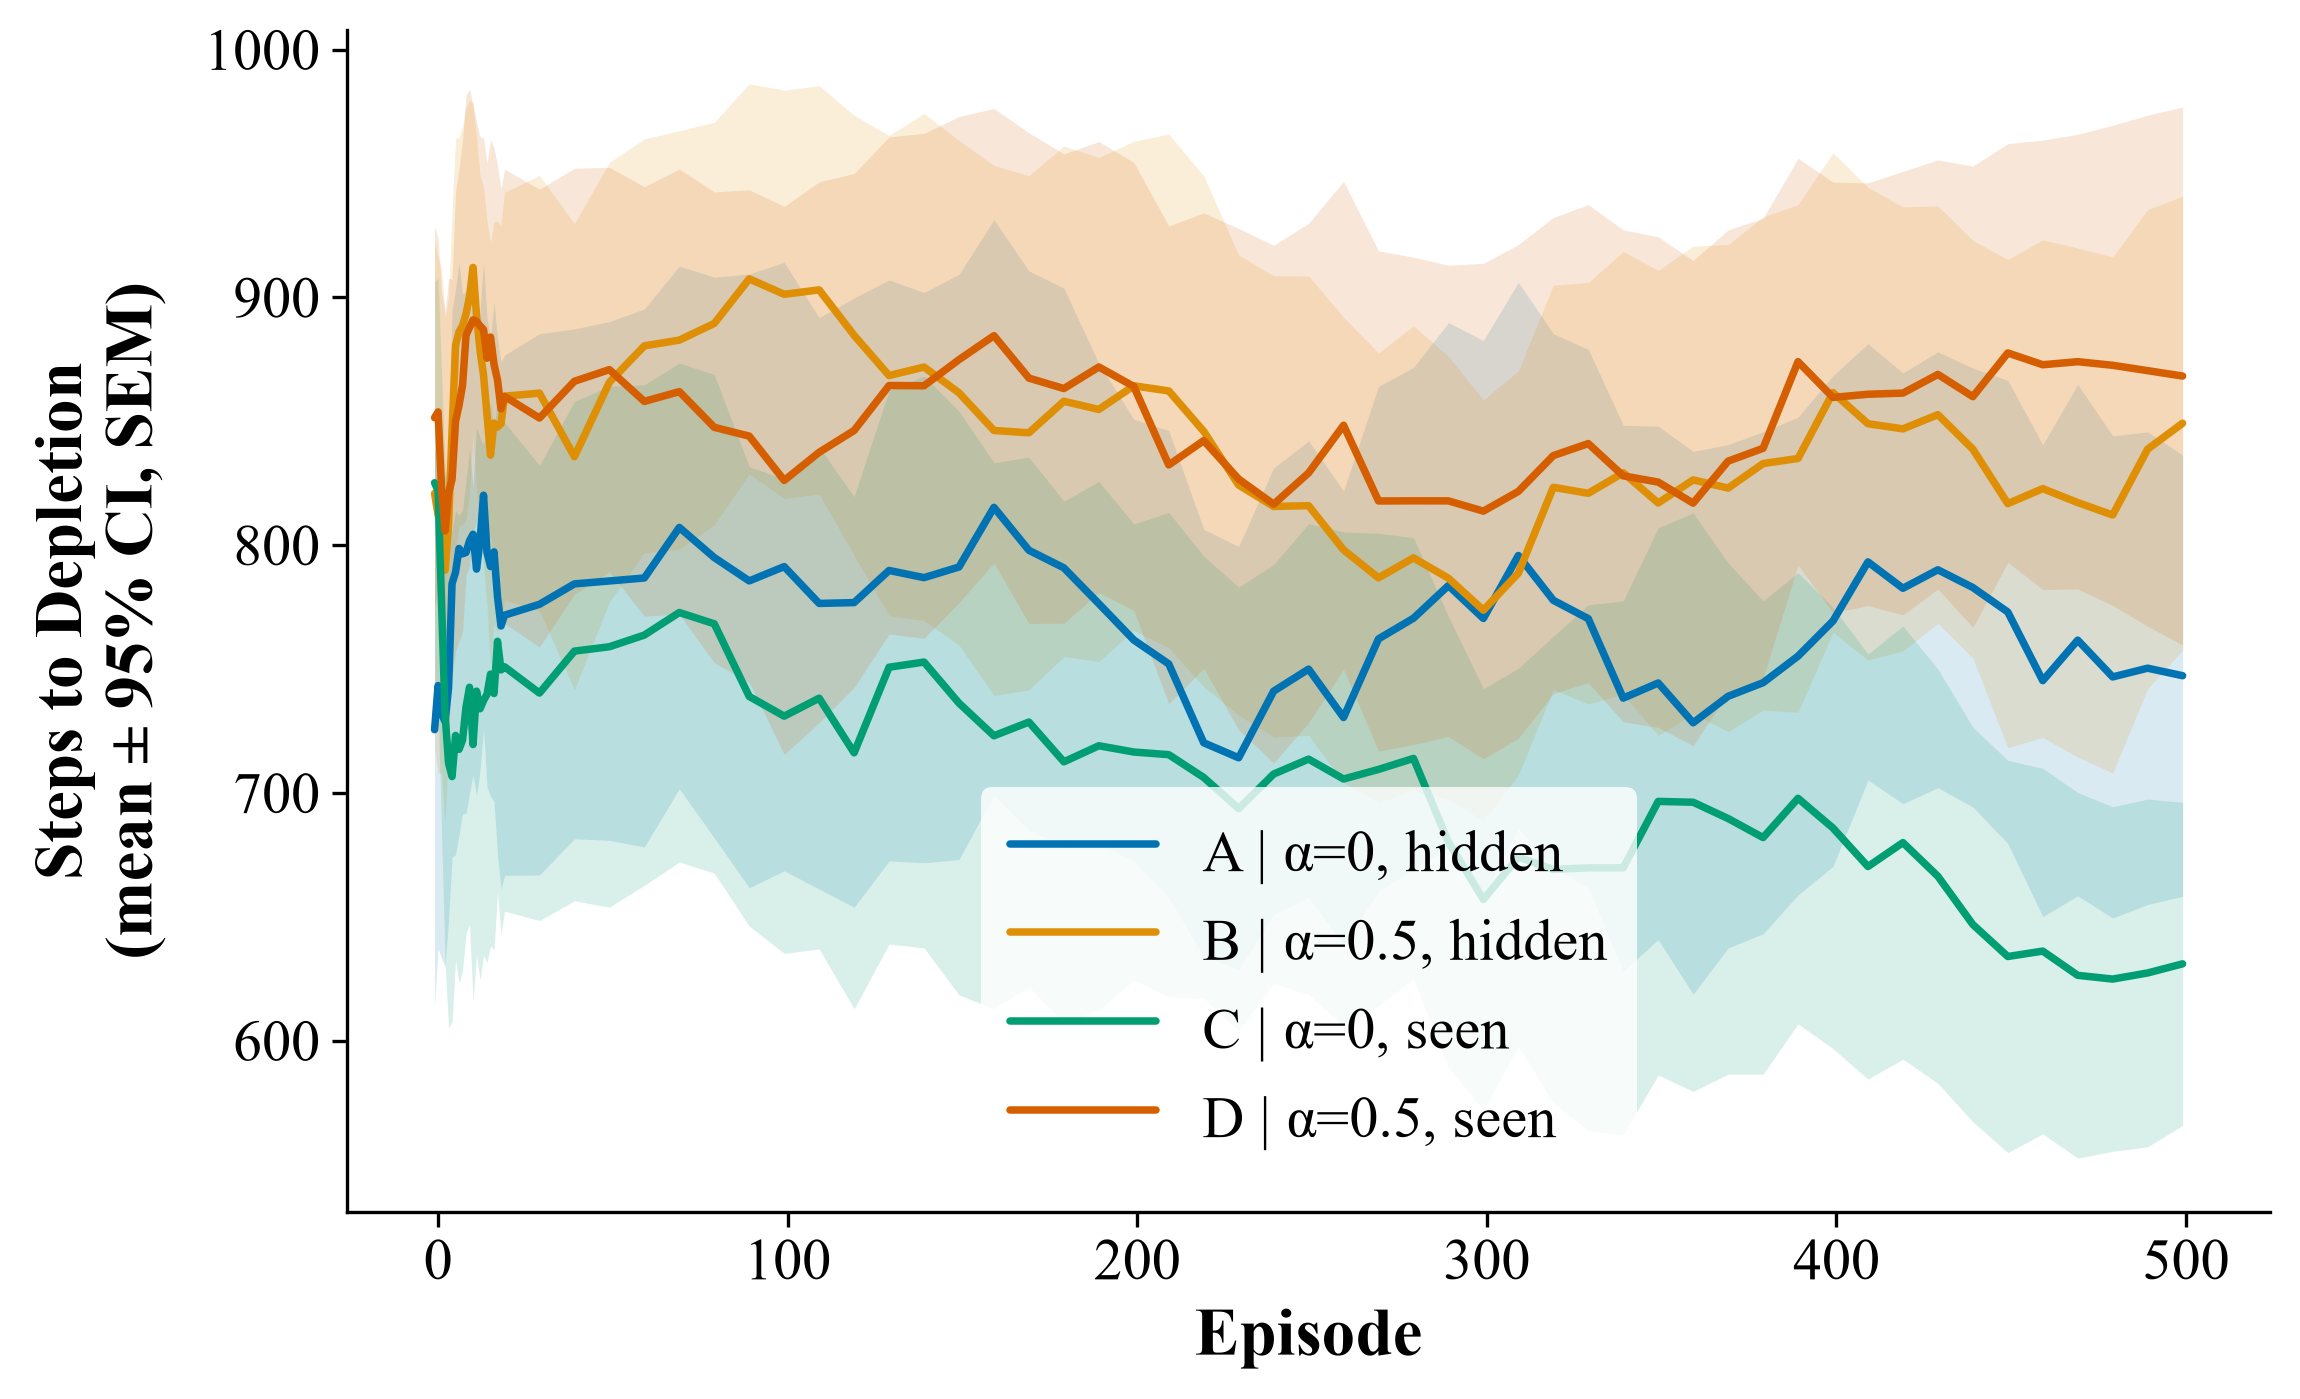


--- Significance tests for depletion_step ---
  A | α=0, hidden vs B | α=0.5, hidden: U=8, p=2.8805e-03, p_adj=1.7283e-02  *
  A | α=0, hidden vs C | α=0, seen: U=81, p=4.1229e-04, p_adj=2.4738e-03  **
  A | α=0, hidden vs D | α=0.5, seen: U=2, p=5.1730e-04, p_adj=3.1038e-03  **
  B | α=0.5, hidden vs C | α=0, seen: U=90, p=2.7970e-04, p_adj=1.6782e-03  **
  B | α=0.5, hidden vs D | α=0.5, seen: U=20, p=2.5692e-02, p_adj=1.5415e-01  ns
  C | α=0, seen vs D | α=0.5, seen: U=0, p=2.7798e-04, p_adj=1.6679e-03  **


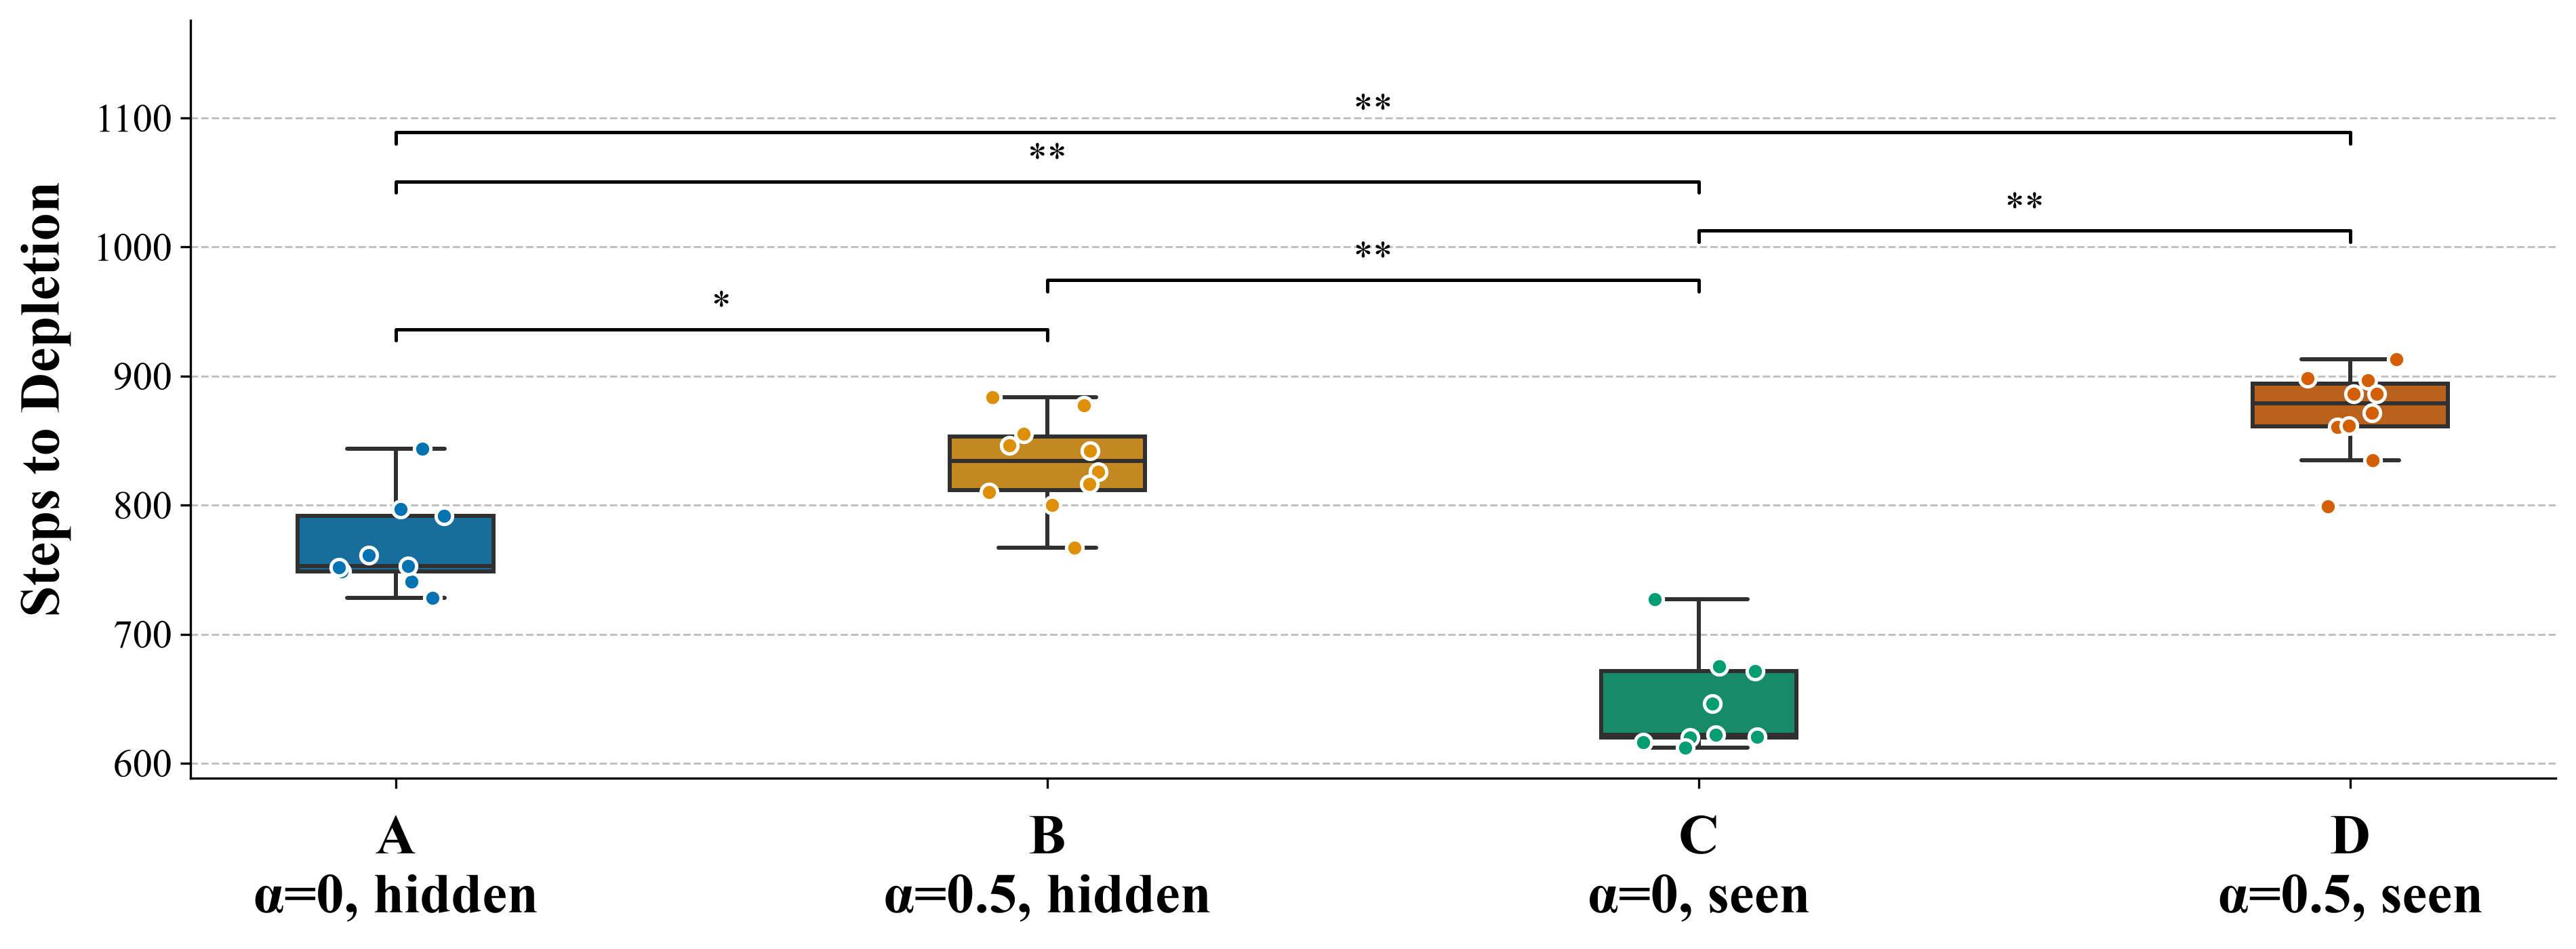


===== steps -- layout '_half' =====


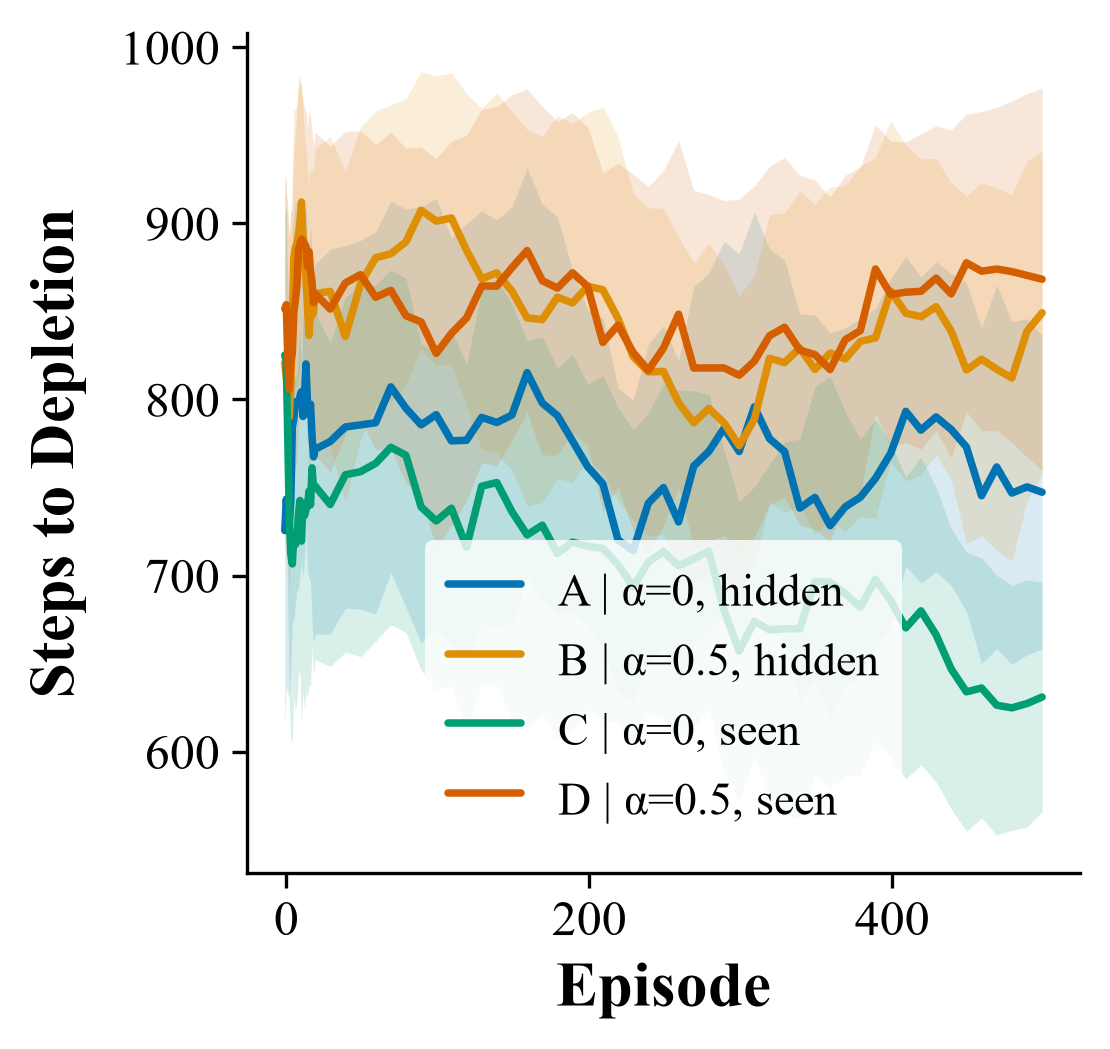

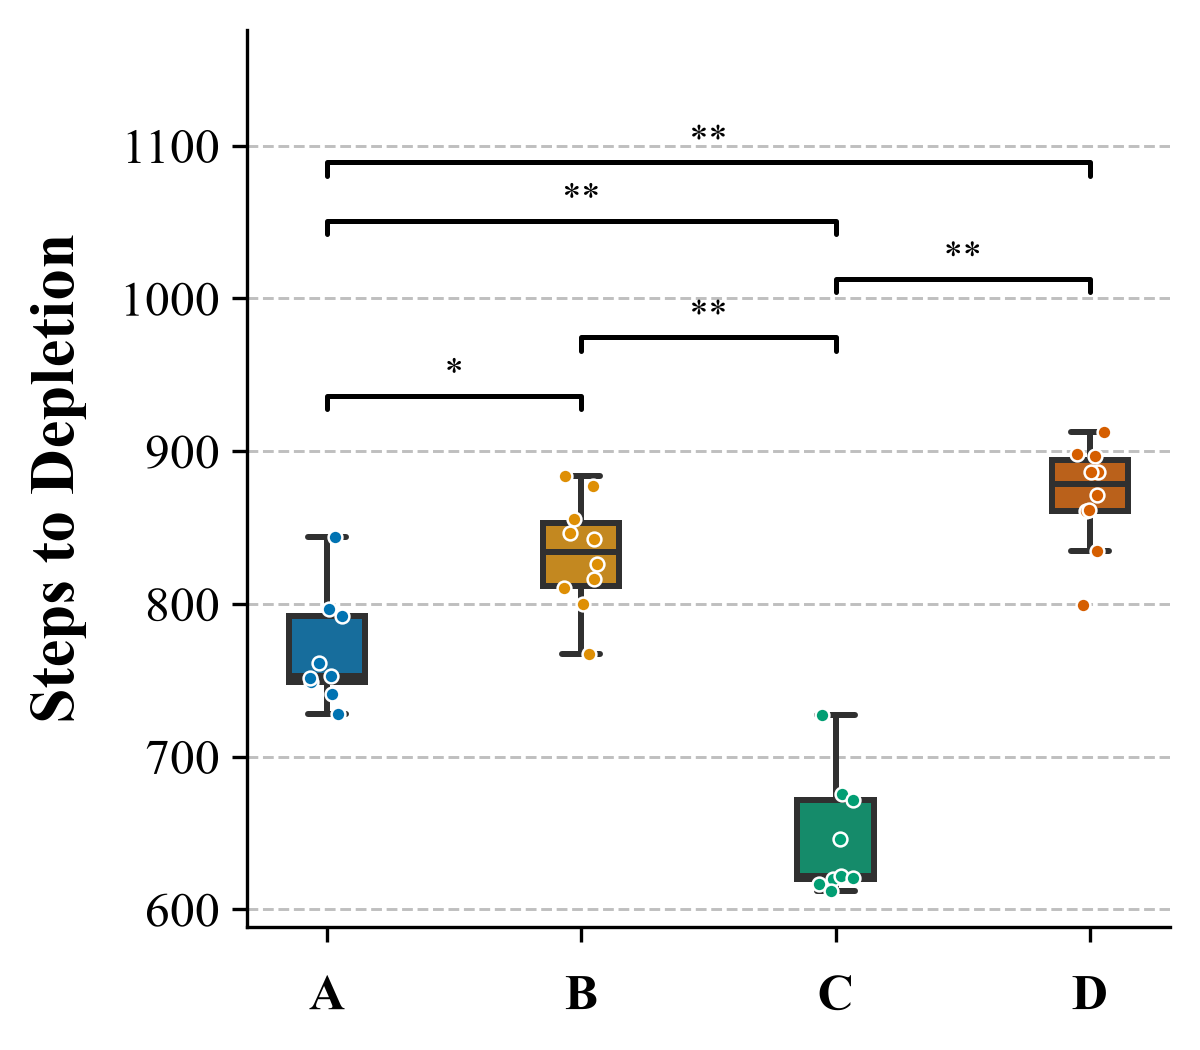


===== gini -- layout 'full' =====


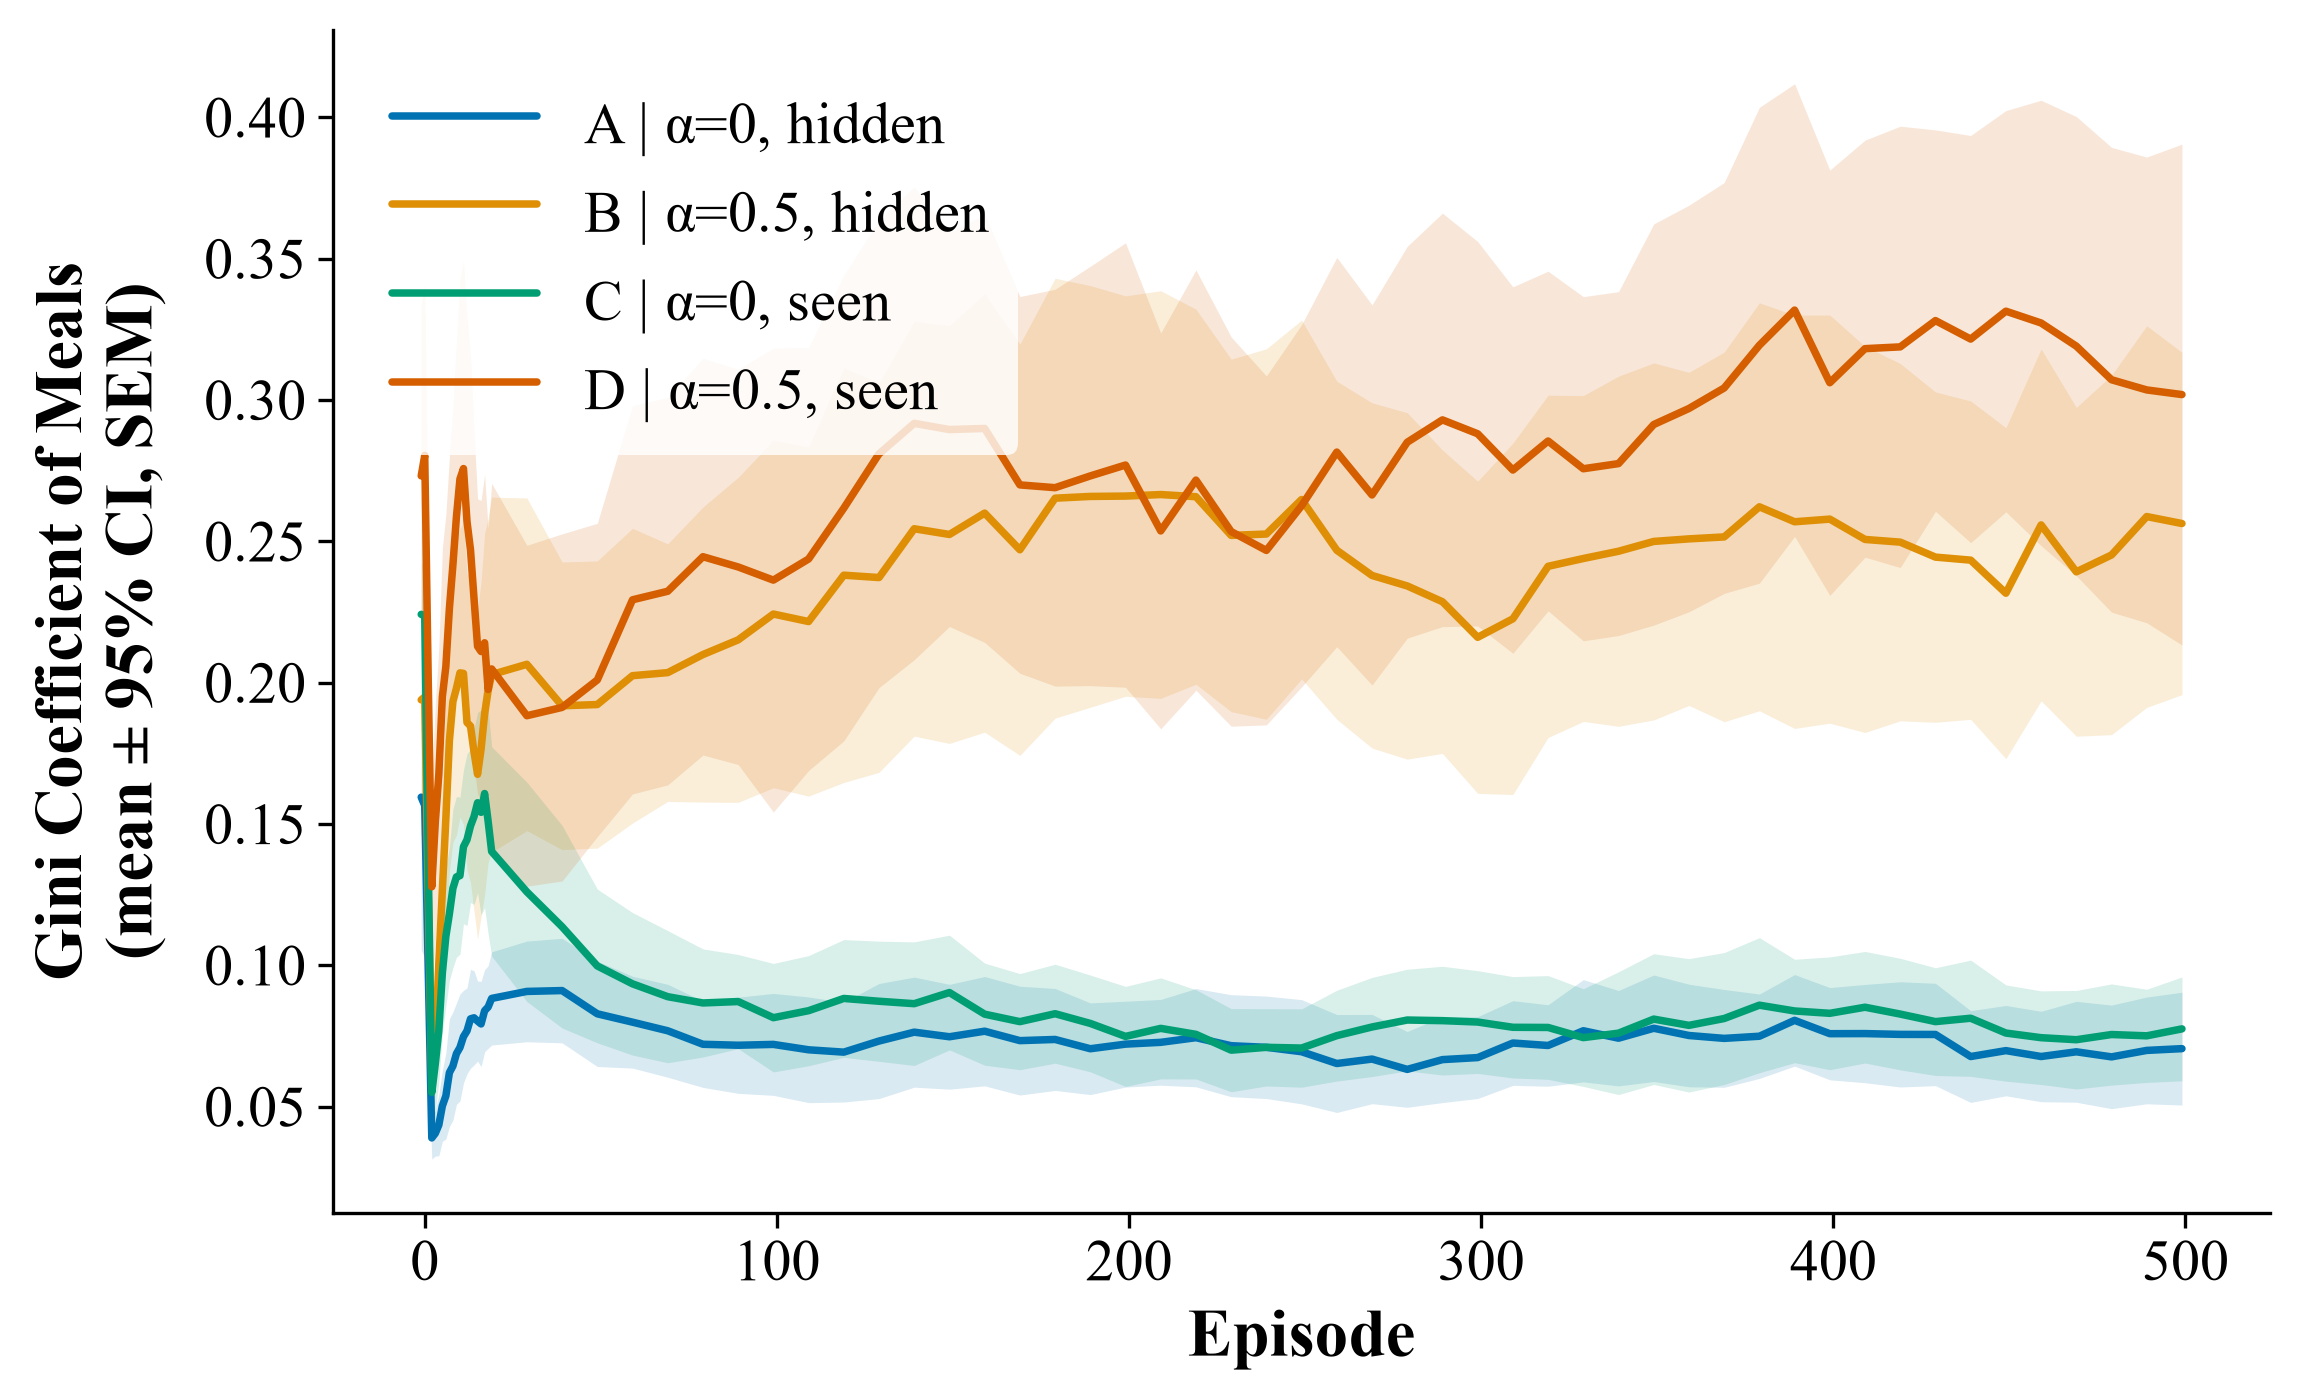


--- Significance tests for gini_meals ---
  A | α=0, hidden vs B | α=0.5, hidden: U=0, p=2.7970e-04, p_adj=1.6782e-03  **
  A | α=0, hidden vs C | α=0, seen: U=26, p=2.1637e-01, p_adj=1.0000e+00  ns
  A | α=0, hidden vs D | α=0.5, seen: U=0, p=2.7970e-04, p_adj=1.6782e-03  **
  B | α=0.5, hidden vs C | α=0, seen: U=90, p=2.7970e-04, p_adj=1.6782e-03  **
  B | α=0.5, hidden vs D | α=0.5, seen: U=4, p=5.8284e-04, p_adj=3.4970e-03  **
  C | α=0, seen vs D | α=0.5, seen: U=0, p=2.7970e-04, p_adj=1.6782e-03  **


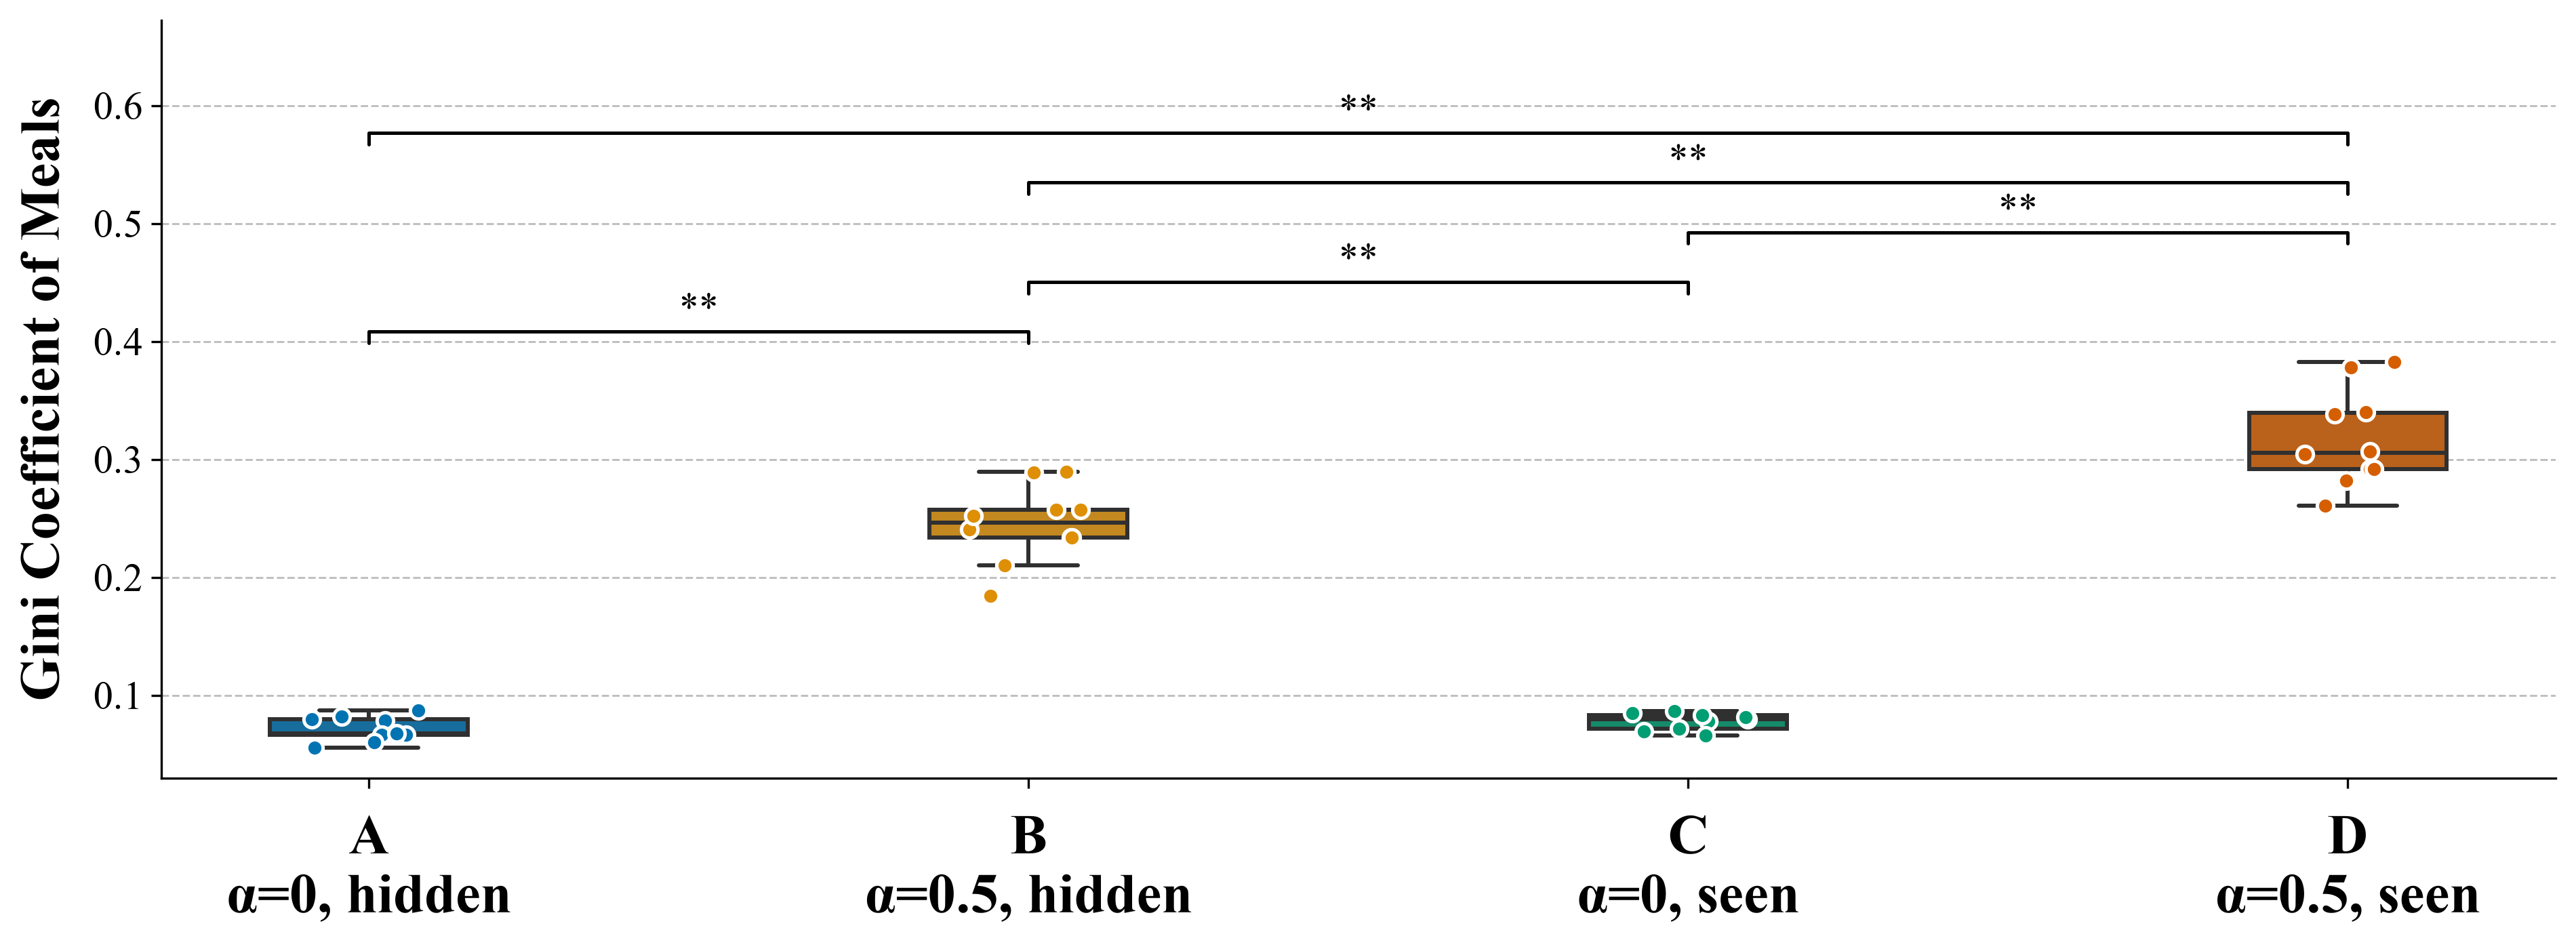


===== gini -- layout '_half' =====


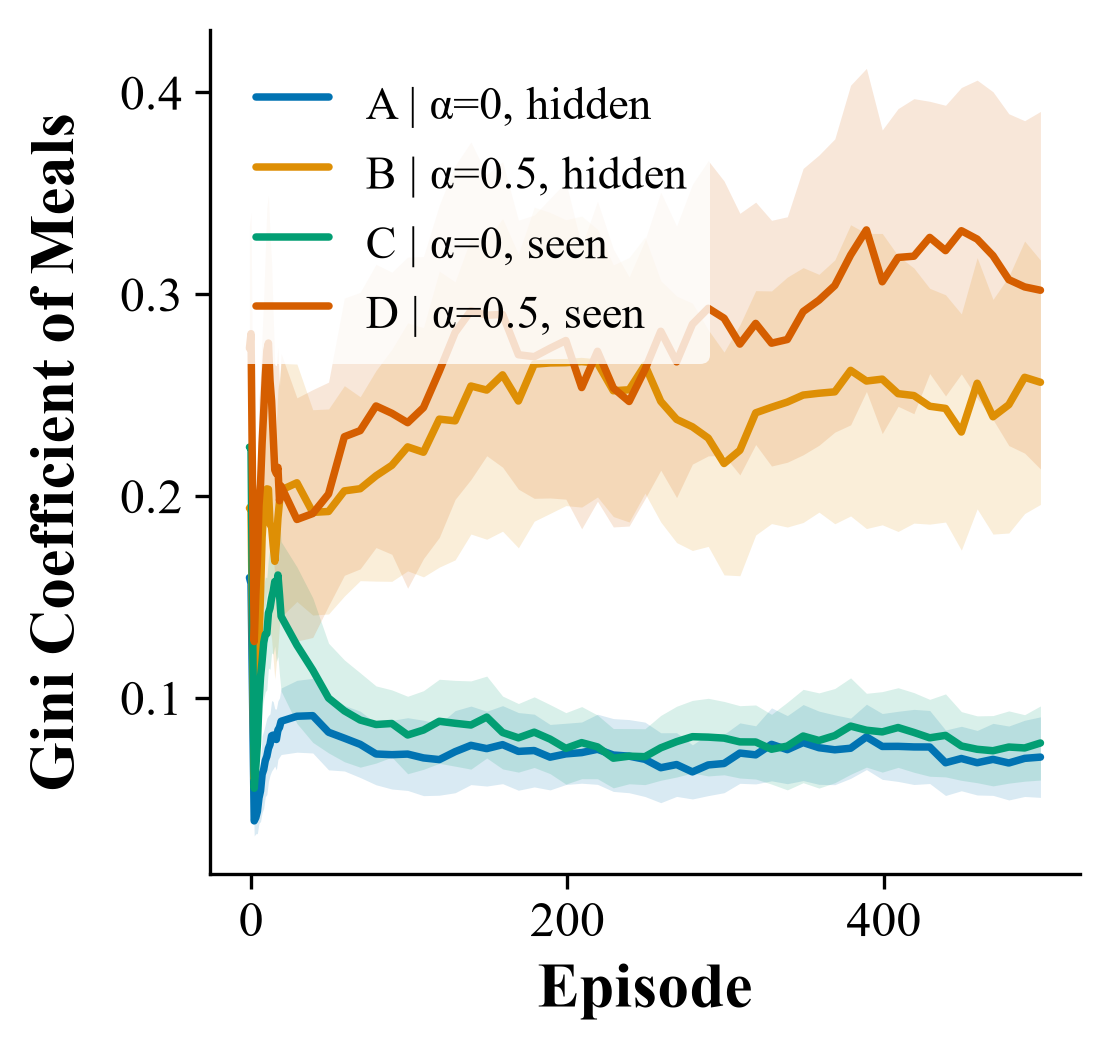

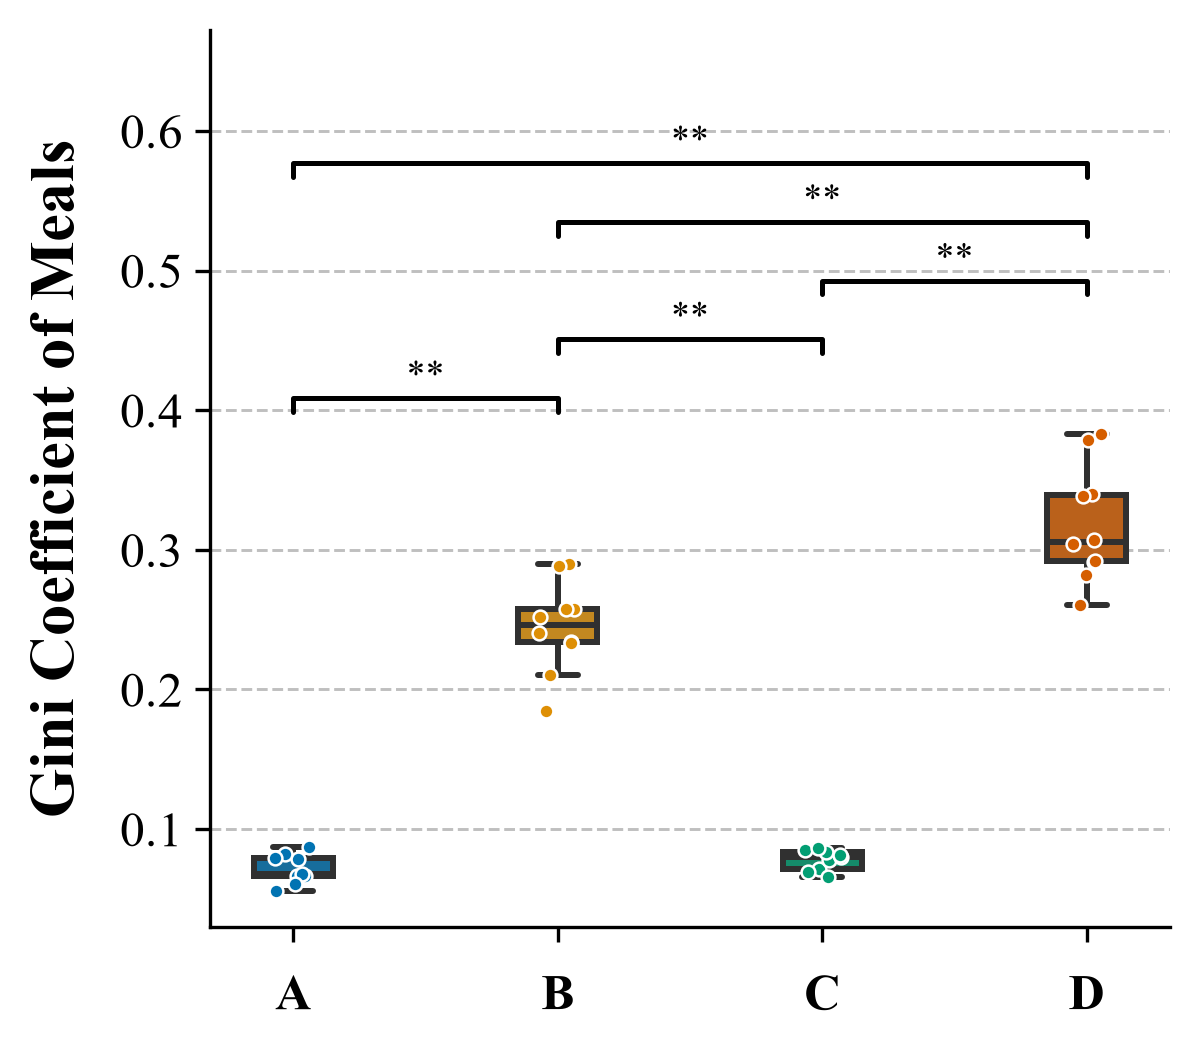


===== reward -- layout 'full' =====


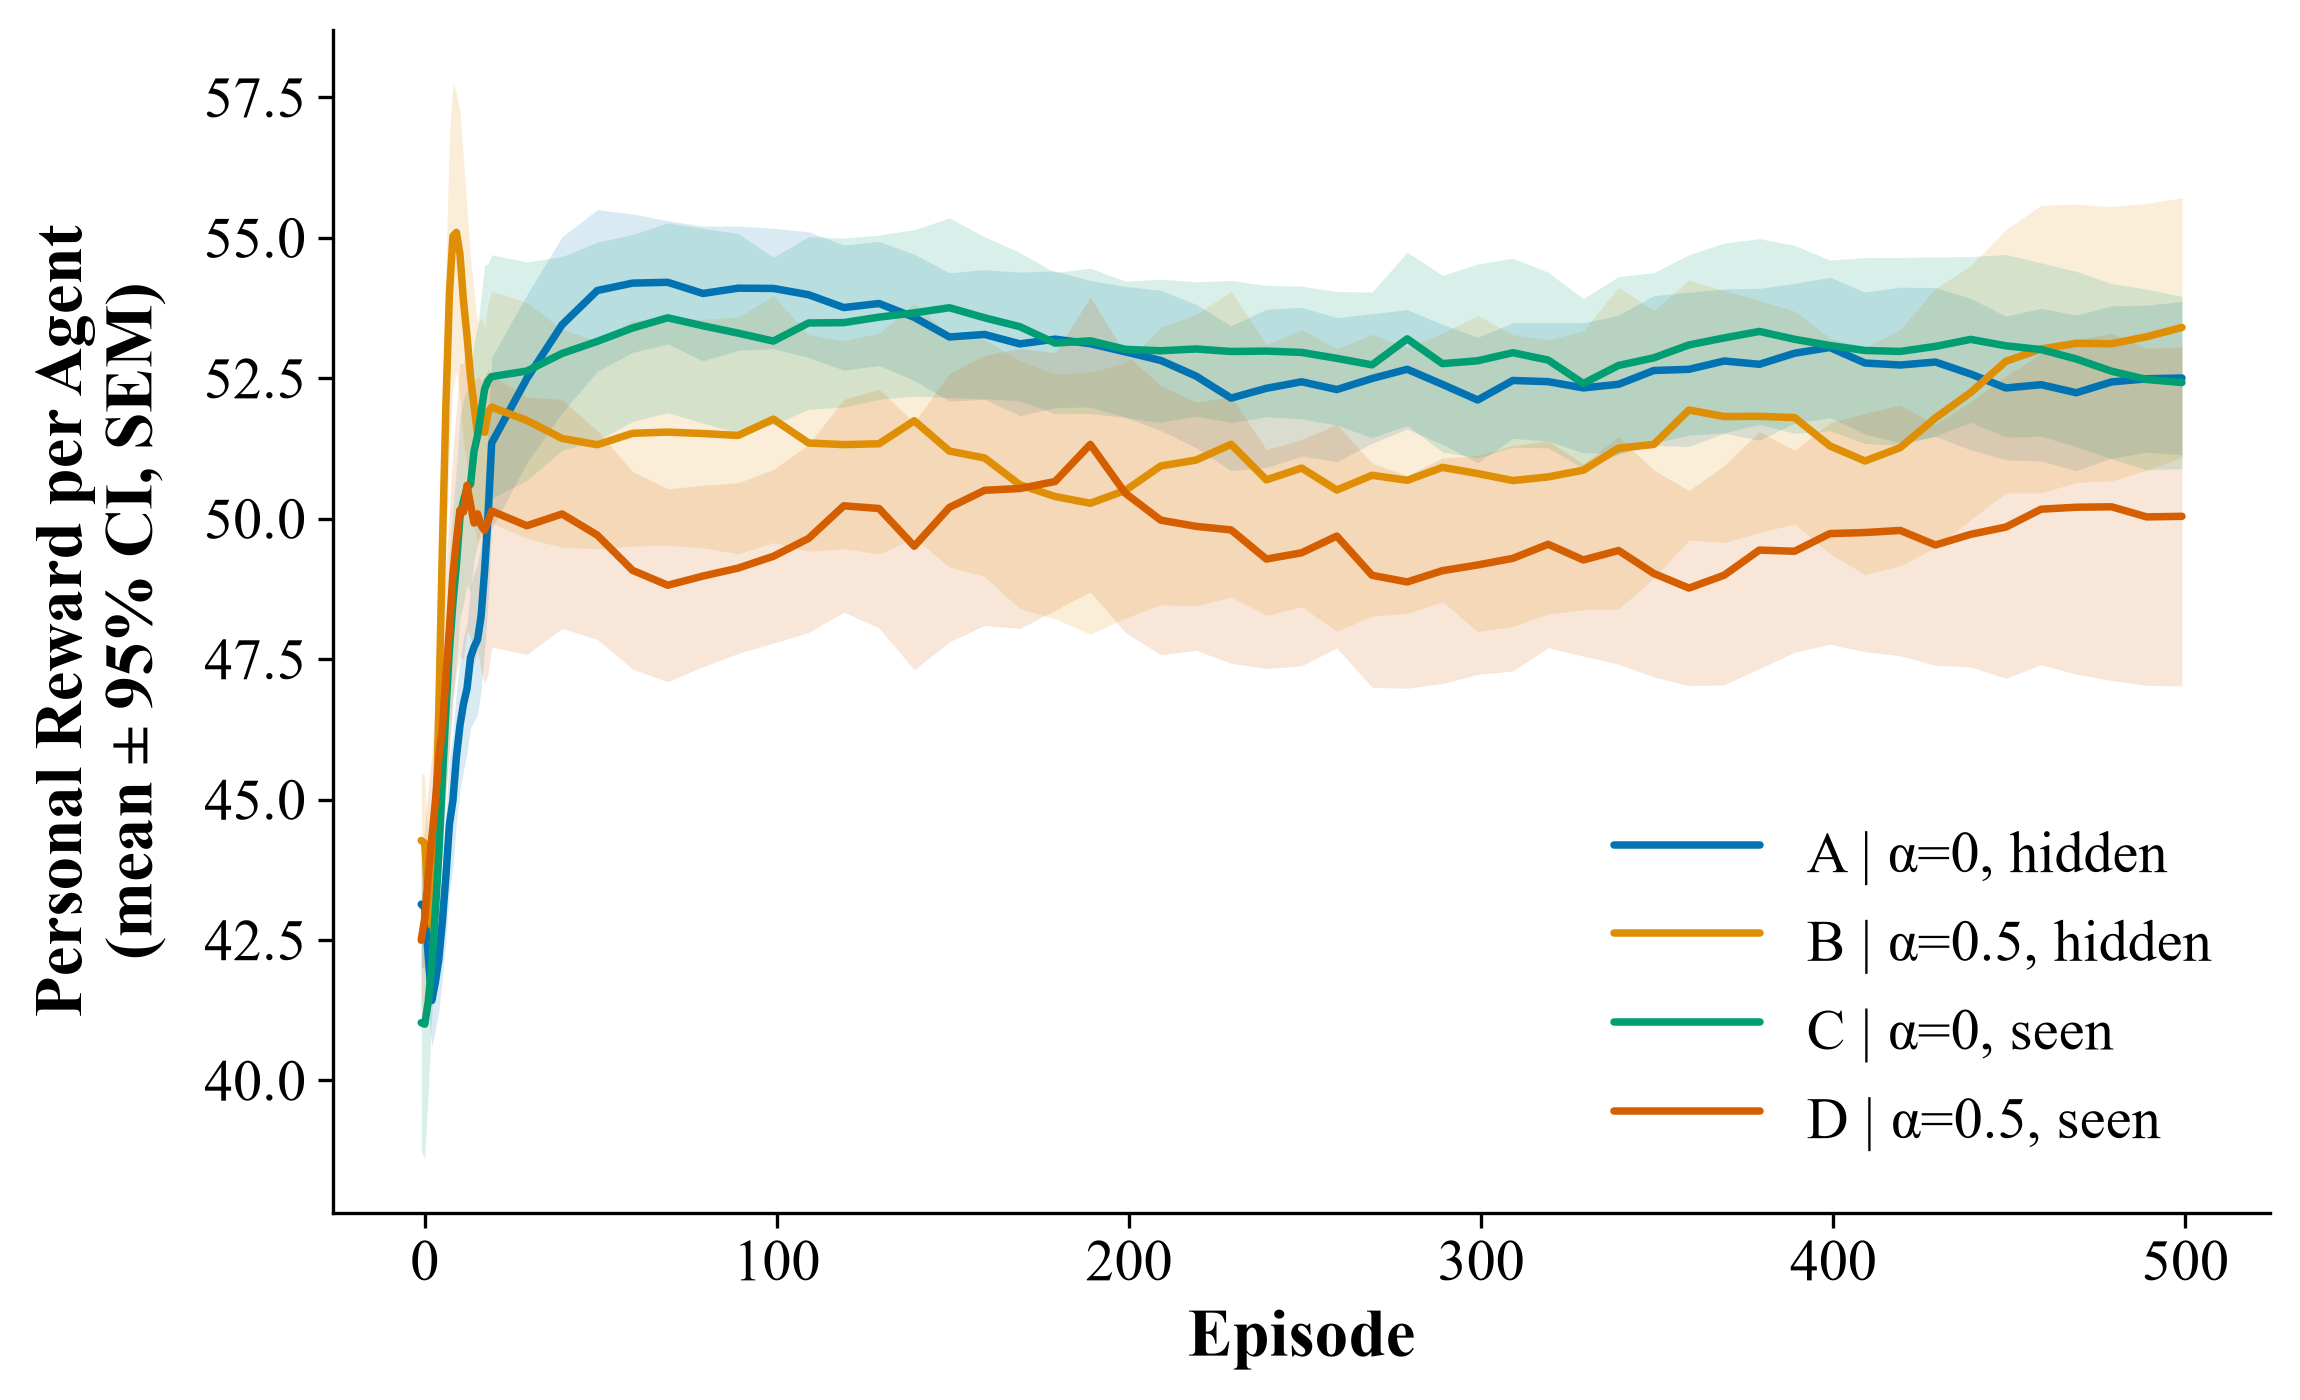


--- Significance tests for personal_reward ---
  A | α=0, hidden vs B | α=0.5, hidden: U=39, p=6.5338e-01, p_adj=1.0000e+00  ns
  A | α=0, hidden vs C | α=0, seen: U=35, p=6.5884e-01, p_adj=1.0000e+00  ns
  A | α=0, hidden vs D | α=0.5, seen: U=82, p=2.8805e-03, p_adj=1.7283e-02  *
  B | α=0.5, hidden vs C | α=0, seen: U=47, p=9.0252e-01, p_adj=1.0000e+00  ns
  B | α=0.5, hidden vs D | α=0.5, seen: U=88, p=4.5864e-03, p_adj=2.7518e-02  *
  C | α=0, seen vs D | α=0.5, seen: U=84, p=1.6693e-03, p_adj=1.0016e-02  *


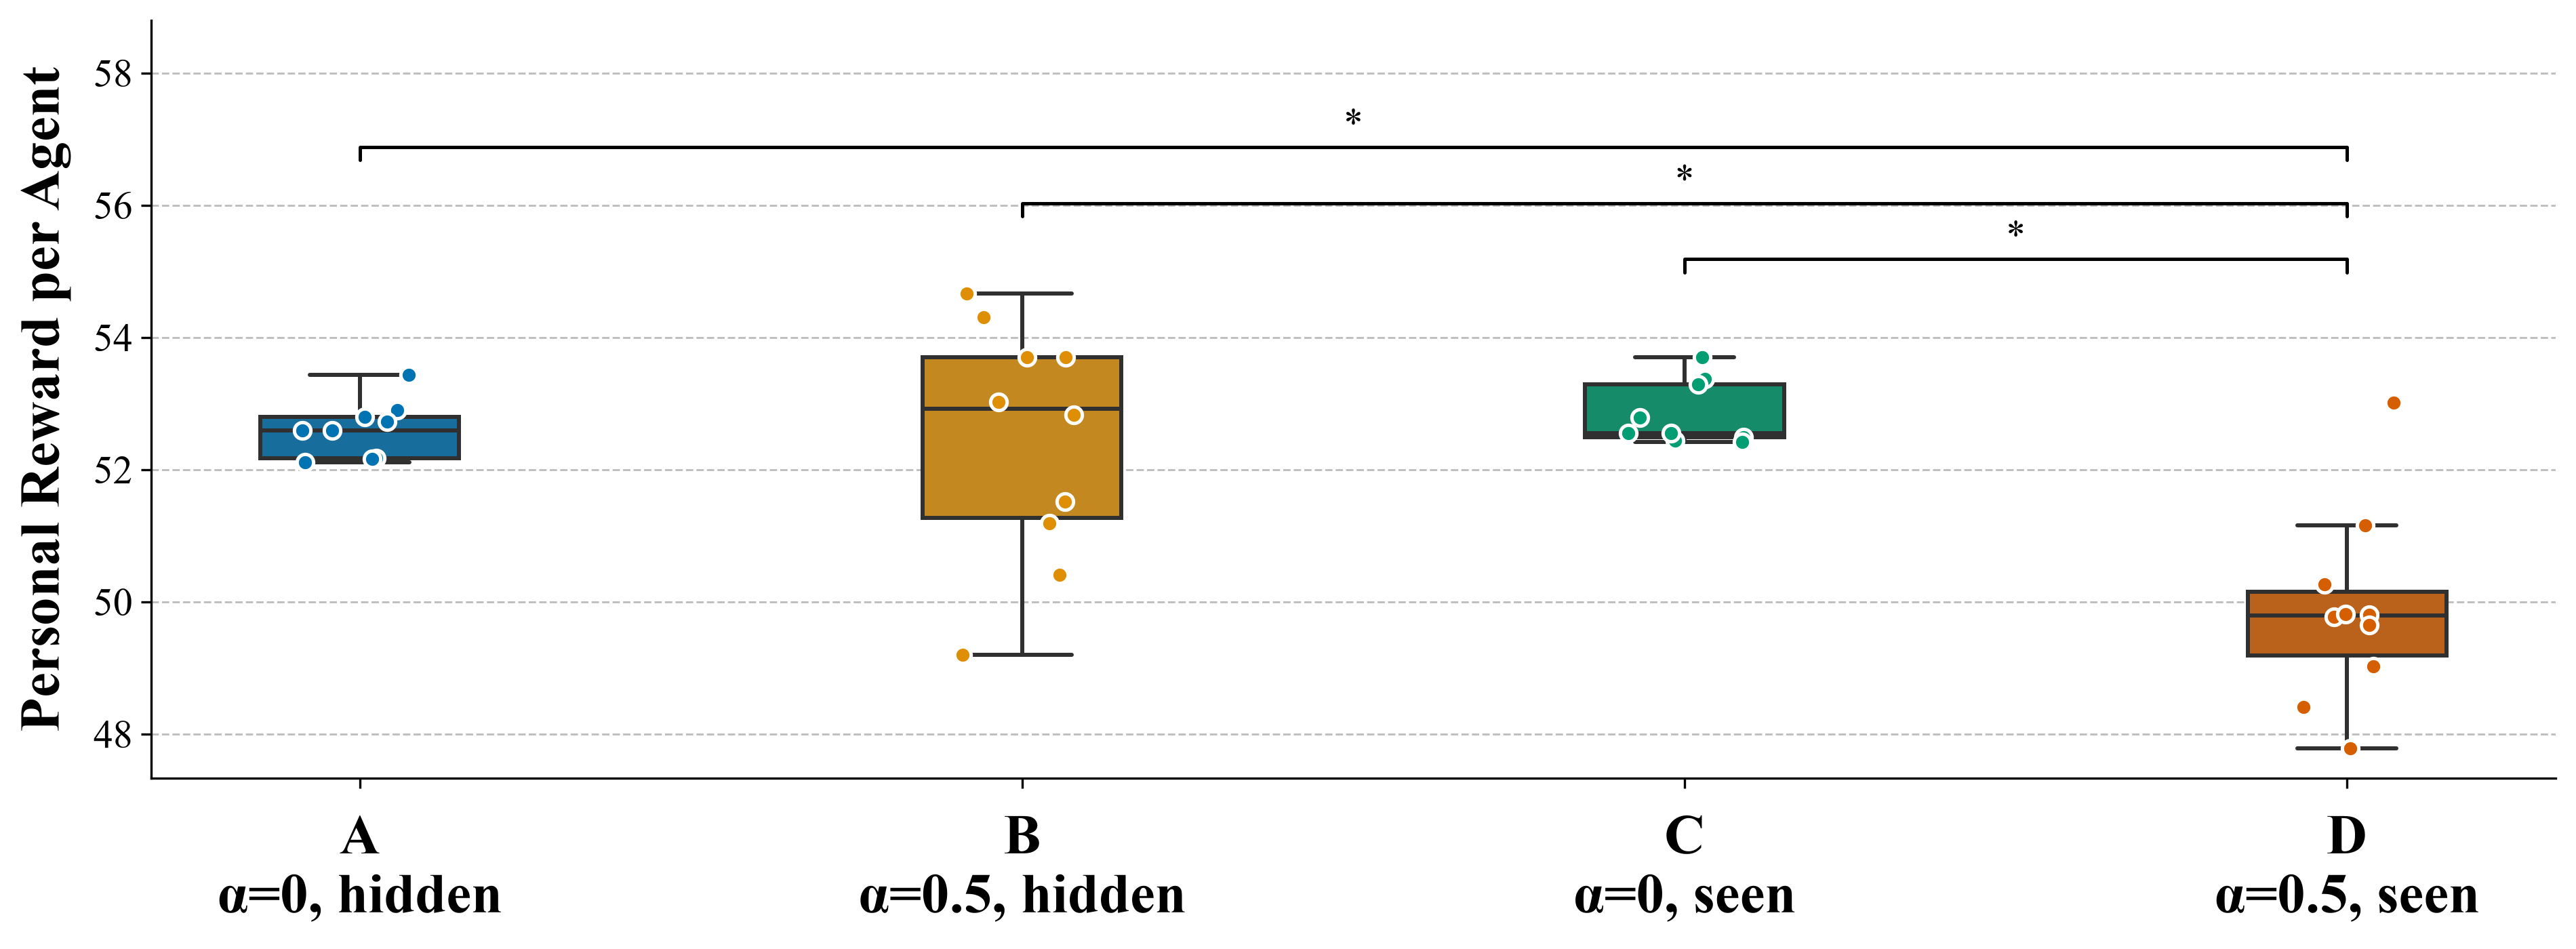


===== reward -- layout '_half' =====


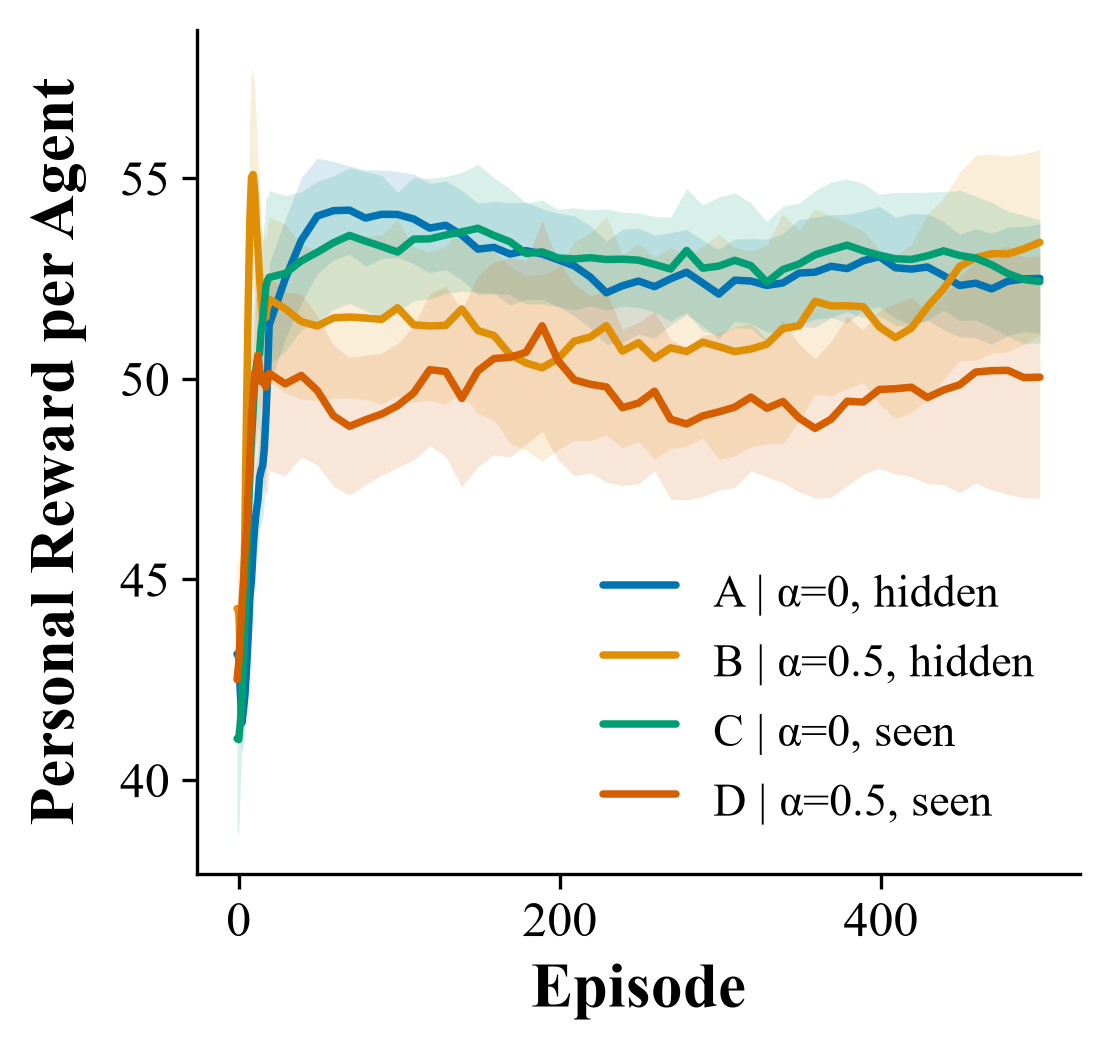

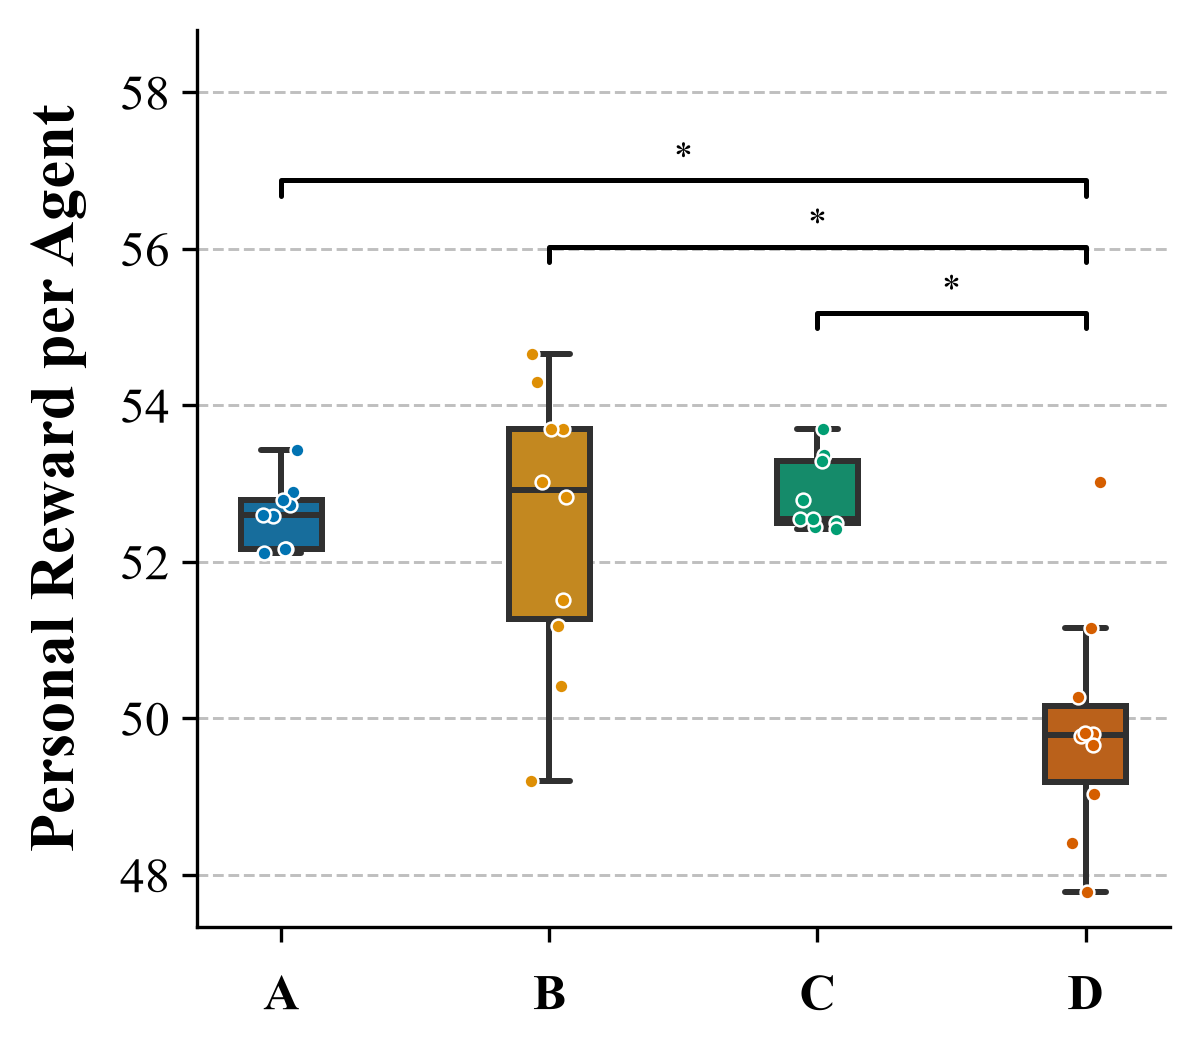

In [18]:
# Poster / manuscript rendering of the two headline metrics. Same numbers as the
# sections above (seed-level means over the last LAST_N_EVAL greedy episodes for
# the boxplots, per-episode means across seeds for the trajectories) -- only the
# house style differs. Figures are shown inline and also written as PDF + PNG
# into FIG_DIR (see below). This cell overwrites the rcParams set in
# section 1, so re-run the
# notebook top-down if the earlier figures are needed again.
from itertools import combinations

import seaborn as sns
from scipy.ndimage import uniform_filter1d
from scipy.stats import norm as _norm, mannwhitneyu

from visualisation_module_test import (
    create_poster_config, apply_style,
    POSTER_BG, POSTER_PALETTE,
)

# -- OUTPUT -------------------------------------------------------------------
# 03_GT figures (journal version). PDF for LaTeX, PNG for slides and quick
# review. Kept inside 03_GT so the AIS 2026 manuscript figures are never
# overwritten.
FIG_DIR = (Path("..") / "figures" / EXPERIMENT
           / ("" if RUN_BATCH == EXPERIMENT else BATCH_TAG)).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIG_PREFIX = "exp1"

def save_fig(fig, name, tight=True):
    # tight=False keeps the canvas at exactly figsize, so the printed aspect
    # ratio is predictable -- required for the side-by-side panels, whose
    # LaTeX widths are computed from it.
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", format=ext,
                    bbox_inches="tight" if tight else None, dpi=300,
                    facecolor=fig.get_facecolor())

# -- CONFIG -------------------------------------------------------------------
config = create_poster_config()
config.label_fontsize = config.label_size = 16
config.tick_fontsize  = config.tick_size  = 14
config.legend_fontsize = config.legend_size = 14
apply_style(config)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif":  ["Times New Roman"],
    "axes.edgecolor":  "black",
    "axes.labelcolor": "black",
    "xtick.color":     "black",
    "ytick.color":     "black",
    "text.color":      "black",
})

BOX_WIDTH  = 0.30

# Two renderings of the same figures:
#   ""      full-width poster / manuscript version (geometry unchanged)
#   "_half" sized for the side-by-side (a)/(b) layout in Results.tex, where the
#           panels are printed at 0.37 and 0.60 of the 12.2 cm LNCS text width.
#           Halving the canvas takes the print reduction from ~23% to ~49%, so
#           labels land near 8 pt instead of the 4 pt of the full-size files.
LAYOUTS = {
    "": dict(fig_w=8.0, fig_h=5.0, fig_w_box=13.0,
             label_fs=16, tick_fs=14, legend_fs=14, legend_ncol=1, handlelen=2.5,
             box_label_fs=20, box_tick_fs=20, star_fs=14,
             line_w=None, pad=0.8,
             pt_size=34, pt_edge=1.2, pt_jitter=0.09,
             ci_in_ylabel=True, short_labels=False, tight=True),
    # The boxplot goes from 13:5 to a near-square canvas: at half width a
    # 2.7 aspect leaves a 2.9 cm-tall panel, too flat for the bracket stack.
    # Results.tex shows a single figure row per study, so the panels can be
    # taller than wide: they print ~5.4 cm high on the 12.2 cm LNCS line.
    # Condition names move to the caption/legend, so the x-axis keeps only
    # the short label, and the CI note leaves the y-label (it is in the
    # LaTeX caption already).
    "_half": dict(fig_w=3.6, fig_h=3.4, fig_w_box=3.9,
                  label_fs=15, tick_fs=12, legend_fs=11, legend_ncol=1, handlelen=1.6,
                  box_label_fs=15, box_tick_fs=12, star_fs=9,
                  line_w=1.8, pad=0.15,
                  pt_size=11, pt_edge=0.6, pt_jitter=0.07,
                  ci_in_ylabel=False, short_labels=True, tight=False),
}
POSTER_SMOOTH = 5   # eval episodes; only ~50 eval points per run, so a 15-point
                    # window would flatten the curve instead of denoising it
CI_PCT = 95
_z = _norm.ppf(0.5 + CI_PCT / 200.0)

def _smooth(arr):
    return uniform_filter1d(np.asarray(arr, dtype=float), size=POSTER_SMOOTH)

def _flat(label):
    """Two-line tick labels are unreadable in printed output."""
    return str(label).replace("\n", " | ")

# -- SIGNIFICANCE HELPERS -----------------------------------------------------
def _p_to_stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

def add_sig_brackets(ax, data, x_col, y_col, groups, star_fs=14, verbose=True):
    # Pairwise Mann-Whitney U with Bonferroni correction; draws brackets only for
    # significant pairs.
    pairs = list(combinations(range(len(groups)), 2))
    n_pairs = max(len(pairs), 1)

    sig_pairs = []
    if verbose:
        print(f"\n--- Significance tests for {y_col} ---")
    for i, j in pairs:
        g1 = data[data[x_col] == groups[i]][y_col].dropna()
        g2 = data[data[x_col] == groups[j]][y_col].dropna()
        if len(g1) < 2 or len(g2) < 2:
            continue
        stat, p = mannwhitneyu(g1, g2, alternative='two-sided')
        p_adj = min(p * n_pairs, 1.0)
        star = _p_to_stars(p_adj)
        if verbose:
            print(f"  {_flat(groups[i])} vs {_flat(groups[j])}: "
                  f"U={stat:.0f}, p={p:.4e}, p_adj={p_adj:.4e}  {star}")
        if star != 'ns':
            sig_pairs.append((i, j, star))

    if not sig_pairs:
        if verbose:
            print("  No significant pairs.")
        return

    y_vals = data[y_col].dropna()
    y_range = y_vals.quantile(0.99) - y_vals.quantile(0.01)
    bar_tip = y_range * 0.03
    bar_sep = y_range * 0.13
    y_start = y_vals.max() + y_range * 0.05

    sig_pairs.sort(key=lambda t: t[1] - t[0])

    for k, (i, j, star) in enumerate(sig_pairs):
        y = y_start + k * bar_sep
        ax.plot([i, i, j, j], [y, y + bar_tip, y + bar_tip, y],
                color='black', linewidth=1.2, clip_on=False)
        ax.text((i + j) / 2, y + bar_tip * 1.2, star,
                ha='center', va='bottom', fontsize=star_fs, color='black', clip_on=False)

    ax.set_ylim(top=y_start + len(sig_pairs) * bar_sep + bar_sep * 1.5)

variables = METRICS          # depletion_step, gini_meals, personal_reward
hue = 'group_label'

labels_dict = {
    'depletion_step': {'ylabel': "Steps to Depletion"},
    'gini_meals':     {'ylabel': "Gini Coefficient of Meals"},
    'personal_reward': {'ylabel': "Personal Reward per Agent"},
}

var_short = {'depletion_step': 'steps', 'gini_meals': 'gini', 'personal_reward': 'reward'}

palette = sns.color_palette(POSTER_PALETTE)

# -- GROUPS: the four cells of the 2x2 -----------------------------------------
GROUP_LABEL = {
    "A": "A\nα=0, hidden",
    "B": "B\nα=0.5, hidden",
    "C": "C\nα=0, seen",
    "D": "D\nα=0.5, seen",
}
group_order = [GROUP_LABEL[c] for c in ["A", "B", "C", "D"]]

box_df = seed_df.copy()                       # one row per (cell, seed)
box_df[hue] = box_df["cell"].map(GROUP_LABEL)

traj_df = ev.copy()                           # one row per (cell, seed, episode)
traj_df[hue] = traj_df["condition"].map(CELL_LETTER).map(GROUP_LABEL)

# -- SEED COUNTS PER CONDITION ------------------------------------------------
sim_counts = (box_df.groupby(hue, observed=True)["seed"].nunique()
                    .reindex(group_order).rename("n_seeds")
                    .reset_index().rename(columns={hue: "Condition"}))
sim_counts["Condition"] = sim_counts["Condition"].map(_flat)
print("Seeds per condition:")
display(sim_counts)

# -- PLOT LOOP ----------------------------------------------------------------
def render(variable, L, suffix):
    """Draw the trajectory and boxplot for one metric under one layout."""
    ylabel = labels_dict[variable]['ylabel']
    vname = var_short[variable]
    groups = group_order
    line_w = L["line_w"] or config.line_width

    # -- TRAJECTORY FIGURE ----------------------------------------------------
    fig_traj, ax_traj = plt.subplots(figsize=(L["fig_w"], L["fig_h"]), dpi=config.dpi)
    fig_traj.patch.set_facecolor(POSTER_BG)
    ax_traj.set_facecolor(POSTER_BG)

    for i, group in enumerate(groups):
        color = palette[i % len(palette)]
        subset = traj_df[traj_df[hue] == group]
        grouped = subset.groupby("episode", observed=True)[variable]
        xs, ys = grouped.mean().index.values, _smooth(grouped.mean().values)
        sem_s = _smooth(grouped.sem().values)

        ax_traj.fill_between(xs, ys - _z * sem_s, ys + _z * sem_s, alpha=0.15, color=color, linewidth=0)
        ax_traj.plot(xs, ys, color=color, linewidth=line_w, label=_flat(group))

    ax_traj.set_xlabel("Episode", fontsize=L["label_fs"], labelpad=4, color="black", fontweight='bold')
    ylab_traj = f"{ylabel}\n(mean ± 95% CI, SEM)" if L["ci_in_ylabel"] else ylabel
    ax_traj.set_ylabel(ylab_traj, fontsize=L["label_fs"], labelpad=8,
                       color="black", fontweight='bold')
    ax_traj.legend(title=None, fontsize=L["legend_fs"], ncol=L["legend_ncol"], columnspacing=1.0,
                   frameon=True, facecolor="white", edgecolor="none", labelcolor="black",
                   handlelength=L["handlelen"], handleheight=1.5, borderpad=0.5)
    sns.despine(ax=ax_traj)
    ax_traj.tick_params(axis="both", labelsize=L["tick_fs"], colors="black", pad=3)
    ax_traj.spines["left"].set_color("black")
    ax_traj.spines["bottom"].set_color("black")
    plt.tight_layout(pad=L["pad"])
    save_fig(fig_traj, f"{FIG_PREFIX}_{vname}_trajectory{suffix}", tight=L["tight"])
    display(fig_traj)
    plt.close(fig_traj)

    # -- BOXPLOT FIGURE -------------------------------------------------------
    fig_box, ax_box = plt.subplots(figsize=(L["fig_w_box"], L["fig_h"]), dpi=config.dpi)
    fig_box.patch.set_facecolor(POSTER_BG)
    ax_box.set_facecolor(POSTER_BG)

    sns.boxplot(data=box_df, x=hue, y=variable,
                order=groups, hue=hue, hue_order=groups,
                width=BOX_WIDTH, linewidth=line_w * 0.8,
                showfliers=False, legend=False, ax=ax_box)

    ax_box.yaxis.grid(True, linestyle='--', linewidth=0.7, color='gray', alpha=0.5, zorder=0)
    ax_box.set_axisbelow(True)

    # -- PER-SEED POINTS ------------------------------------------------------
    # Same overlay as box_strip() in section 11: at ten seeds per cell the box
    # alone hides the n and the shape of the spread. Fliers are off above
    # because these points already show the extremes -- otherwise the outliers
    # would be drawn twice. The jitter is seeded, so re-running the cell writes
    # the same figure. Colours come from the same POSTER_PALETTE index seaborn
    # gives the boxes (sns.set_palette in apply_style), so points and boxes match.
    rng = np.random.default_rng(0)
    for i, group in enumerate(groups):
        values = box_df.loc[box_df[hue] == group, variable].to_numpy()
        jitter = i + rng.uniform(-L["pt_jitter"], L["pt_jitter"], size=len(values))
        ax_box.scatter(jitter, values, s=L["pt_size"],
                       color=palette[i % len(palette)], zorder=3,
                       edgecolor=POSTER_BG, linewidth=L["pt_edge"])

    # -- SIGNIFICANCE BRACKETS ------------------------------------------------
    # All pairwise comparisons are kept in both layouts; only the star size changes.
    add_sig_brackets(ax_box, box_df, hue, variable, groups,
                     star_fs=L["star_fs"], verbose=(suffix == ""))

    ax_box.set_xlabel("")
    ax_box.set_ylabel(ylabel, fontsize=L["box_label_fs"], labelpad=8, color="black", fontweight='bold')
    ax_box.set_xticks(range(len(groups)))
    # Two-line tick labels do not fit a near-square half-width panel; the
    # first line ("A", "alpha = 0.50", ...) identifies the group on its own.
    xticklabels = [g.split("\n")[0] for g in groups] if L["short_labels"] else groups
    ax_box.set_xticklabels(xticklabels, fontsize=L["box_tick_fs"], rotation=0,
                           ha="center", color="black", fontweight='bold')
    ax_box.tick_params(axis="x", pad=8, colors="black")
    ax_box.tick_params(axis="y", labelsize=L["tick_fs"], colors="black", pad=3)
    ax_box.spines["left"].set_color("black")
    ax_box.spines["bottom"].set_color("black")
    sns.despine(ax=ax_box)
    plt.tight_layout(pad=L["pad"])
    save_fig(fig_box, f"{FIG_PREFIX}_{vname}_boxplot{suffix}", tight=L["tight"])
    display(fig_box)
    plt.close(fig_box)


for variable in variables:
    for suffix, L in LAYOUTS.items():
        print(f"\n===== {var_short[variable]} -- layout '{suffix or 'full'}' =====")
        render(variable, L, suffix)


### Results paragraph

To be written once the full campaign (target 20 seeds per cell) has landed; read
the numbers from §12 and the test printouts of §13. The AIS 2026 paragraph that
used to sit here described the 02_GT_AIS runs and no longer applies.
